In [21]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
from helper_files.maoa_plate_loader import *
from helper_files.mea_feats_analysis import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings


warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


In [23]:
"""

root_dir = "/Users/blancamartin/Downloads/Sandra_MAOA_MEA/"  # adjust as needed
big_df = summarize_all_spike_files(root_dir, show_progress=True)

"""


'\n\nroot_dir = "/Users/blancamartin/Downloads/Sandra_MAOA_MEA/"  # adjust as needed\nbig_df = summarize_all_spike_files(root_dir, show_progress=True)\n\n'

In [24]:
"""#save as pickle 
with open('/Users/blancamartin/Desktop/Muotri_lab/MAOA_pickles/processed_df.pkl', 'wb') as file:
    pickle.dump(big_df, file)"""

"#save as pickle \nwith open('/Users/blancamartin/Desktop/Muotri_lab/MAOA_pickles/processed_df.pkl', 'wb') as file:\n    pickle.dump(big_df, file)"

In [25]:
#open pickle
with open('/Users/blancamartin/Desktop/Muotri_lab/MAOA_pickles/processed_df.pkl', 'rb') as file:
    big_df = pickle.load(file)

In [26]:
#add experiment group
big_df["experiment"] = big_df.apply(
    lambda row: assign_experiment(row["plate_name"], row["recording_date"]),
    axis=1
)

In [27]:
#remove day sept 26th (bad recording)

#remove bad experiment 
# Convert recording_date safely
big_df["recording_date"] = pd.to_datetime(big_df["recording_date"], errors="coerce")

# Remove all recordings from Sept 26, 2025
remove_date = pd.to_datetime("2025-09-26")
big_df = big_df[big_df["recording_date"] != remove_date]

#### Mutant (c3, c71, c90), WT (c12, c30, c54) and GM

In [28]:
#Remove lines we are not using 
REMOVALS = {
    "MAOA1":{"H9", "C12", "C90", "C54"},
    "MAOA2":{"H9", "C12", "C90", "C54"},
    "MAOA3":{"H9", "C12", "C90", "C54"},
    "MAOA72": {"C12", "C90", "C54"},
    "MAOA76": {"C12", "C90", "C54"},
    "MAOA77": {"C12", "C90", "C54"},
}

In [29]:
big_df = remove_clones_by_plate(big_df, REMOVALS)

Removed 396 rows based on plate-specific clone removal.


In [30]:
big_df

,well,firing_rate_stats_hz,burst_rate_stats_hz,network_event_rate_hz,synchrony_index,electrodes,firing_rate_vector_hz,burst_rate_vector_hz,recording_date,recording_date_str,plate_name,cell_line,organoid_age_days,spike_list_path,experiment
0,A1,"[4.017828444082542, 5.087837151042226]","[0.1869410723704701, 0.15790478861256138]",0.071252,0.099785,"[A1_11, A1_12, A1_13, A1_14, A1_15, A1_16, A1_...","[1.7476564118841798, 0.05145987169760892, nan,...","[0.022431226124598757, 0.0006597419448411399, ...",2025-04-14,04.14.2025,MAOA2,C3,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
1,A2,"[1.4391208230357608, 1.6648439676442284]","[0.09436092897565711, 0.09586305971365496]",0.124031,0.022132,"[A2_11, A2_12, A2_13, A2_14, A2_15, A2_16, A2_...","[3.015680429868851, 0.0006597419448411399, 0.0...","[0.19066542205908946, nan, nan, nan, 0.0032987...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
2,A3,"[0.4052027312243695, 0.5762036681376207]","[0.018160265113258748, 0.024168885783248578]",0.003299,0.000282,"[A3_11, A3_12, A3_13, A3_14, A3_15, A3_16, A3_...","[nan, 0.0006597419448411399, 0.000659741944841...","[nan, nan, nan, nan, 0.00791690333809368, nan,...",2025-04-14,04.14.2025,MAOA2,GM,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
3,B1,"[2.0029325617413787, 2.347922067937726]","[0.1179549150855449, 0.11597167105563749]",0.032327,0.007995,"[B1_11, B1_12, B1_13, B1_14, B1_15, B1_16, B1_...","[2.4403854539673766, 0.0006597419448411399, 3....","[0.07653006560157223, nan, 0.16889393787933182...",2025-04-14,04.14.2025,MAOA2,C71,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
4,B2,"[1.821286102520696, 3.2362072623431377]","[0.1274676415928486, 0.11408226907420285]",0.148442,0.013659,"[B2_11, B2_12, B2_13, B2_14, B2_15, B2_16, B2_...","[0.0013194838896822799, 3.5289596629552578, 0....","[nan, 0.20188103512138883, nan, nan, 0.0936833...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1051,A4,"[0.004241748910561047, 0.009775569618114778]","[nan, nan]",0.000000,0.232831,"[A4_11, A4_12, A4_13, A4_14, A4_15, A4_16, A4_...","[0.0008220443625118308, nan, 0.000822044362511...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,GM,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
1052,B1,"[0.26199502345978026, 0.7419211332715153]","[0.02757010323501217, 0.025920461645713547]",0.000000,0.046000,"[B1_11, B1_12, B1_13, B1_14, B1_15, B1_16, B1_...","[nan, 0.0008220443625118308, 0.002466133087535...","[nan, nan, nan, nan, 0.01808497597526028, nan,...",2025-10-30,10.30.2025,MAOA76,C3,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
1053,B2,"[0.4753718139533415, 1.490921272006652]","[0.03565617422395066, 0.04528512776359013]",0.000000,0.037999,"[B2_11, B2_12, B2_13, B2_14, B2_15, B2_16, B2_...","[0.024661330875354926, 0.17920567102757912, 0....","[nan, 0.007398399262606477, 0.0024661330875354...",2025-10-30,10.30.2025,MAOA76,C71,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
1054,B4,"[0.010609510053668317, 0.045617147944364]","[0.01808497597526028, 0.0]",0.000000,-0.001633,"[B4_11, B4_12, B4_13, B4_14, B4_15, B4_16, B4_...","[0.004932266175070985, 0.0008220443625118308, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,GM,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3


### Exp 1 analysis 


### RUNNING ANALYSIS FOR Exp1 ###
Plates included: ['MAOA2' 'MAOA3' 'MAOA1']

### DRAWING PLATE MAPS ###
 → Plotting MAOA2


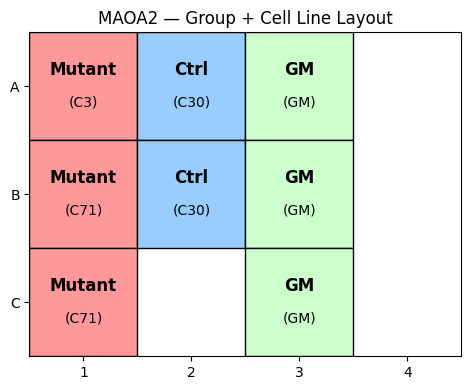

 → Plotting MAOA3


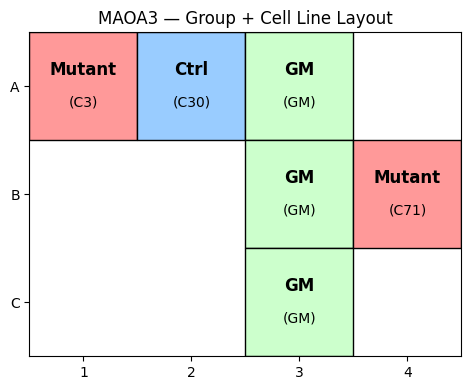

 → Plotting MAOA1


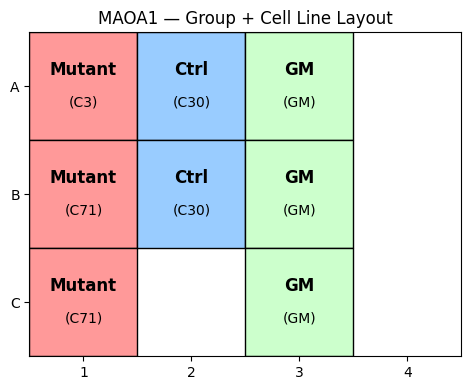


### GENERATING FEATURE PLOTS — CELL LINES ###
 → Plotting firing (cell lines)

=== Plotting Experiment Exp1 ===


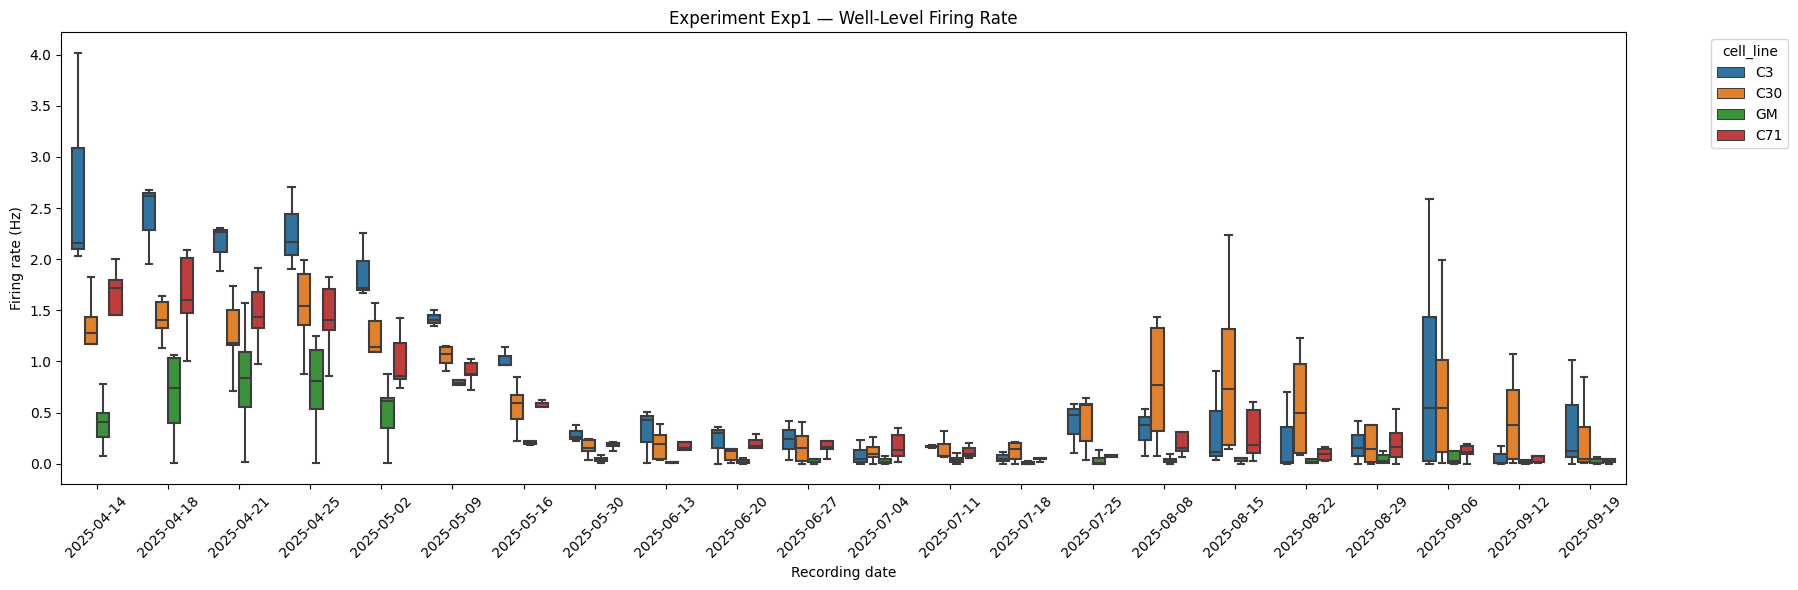

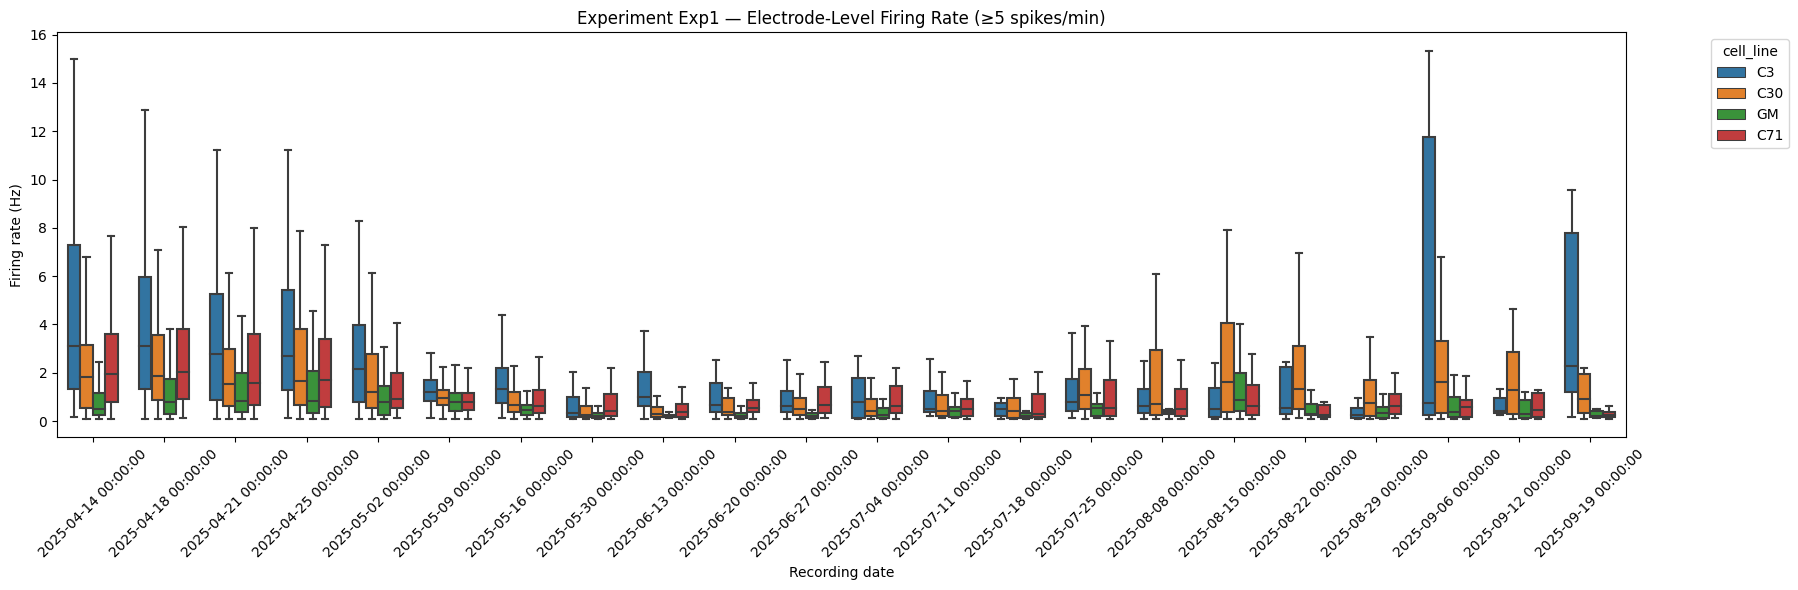

 → Plotting burst (cell lines)

=== Plotting Experiment Exp1 ===


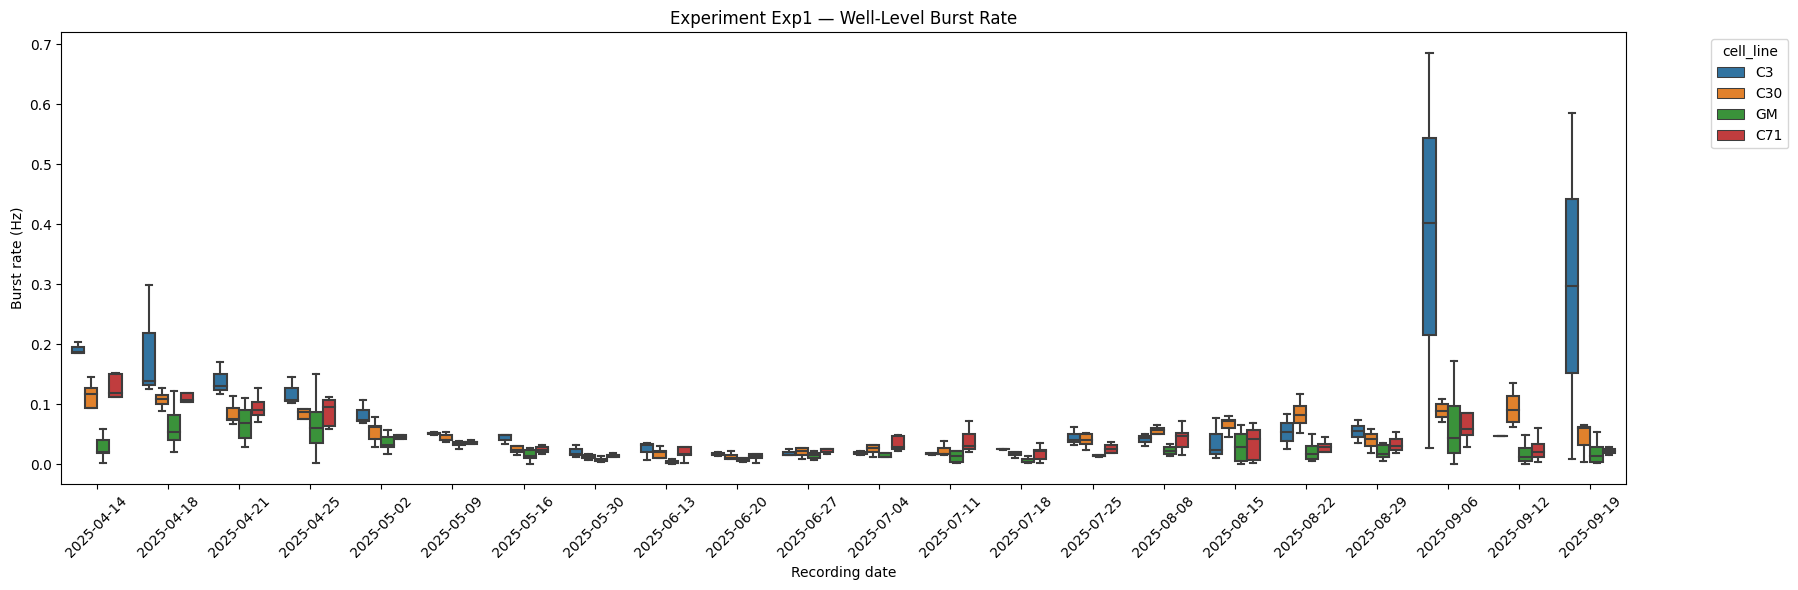

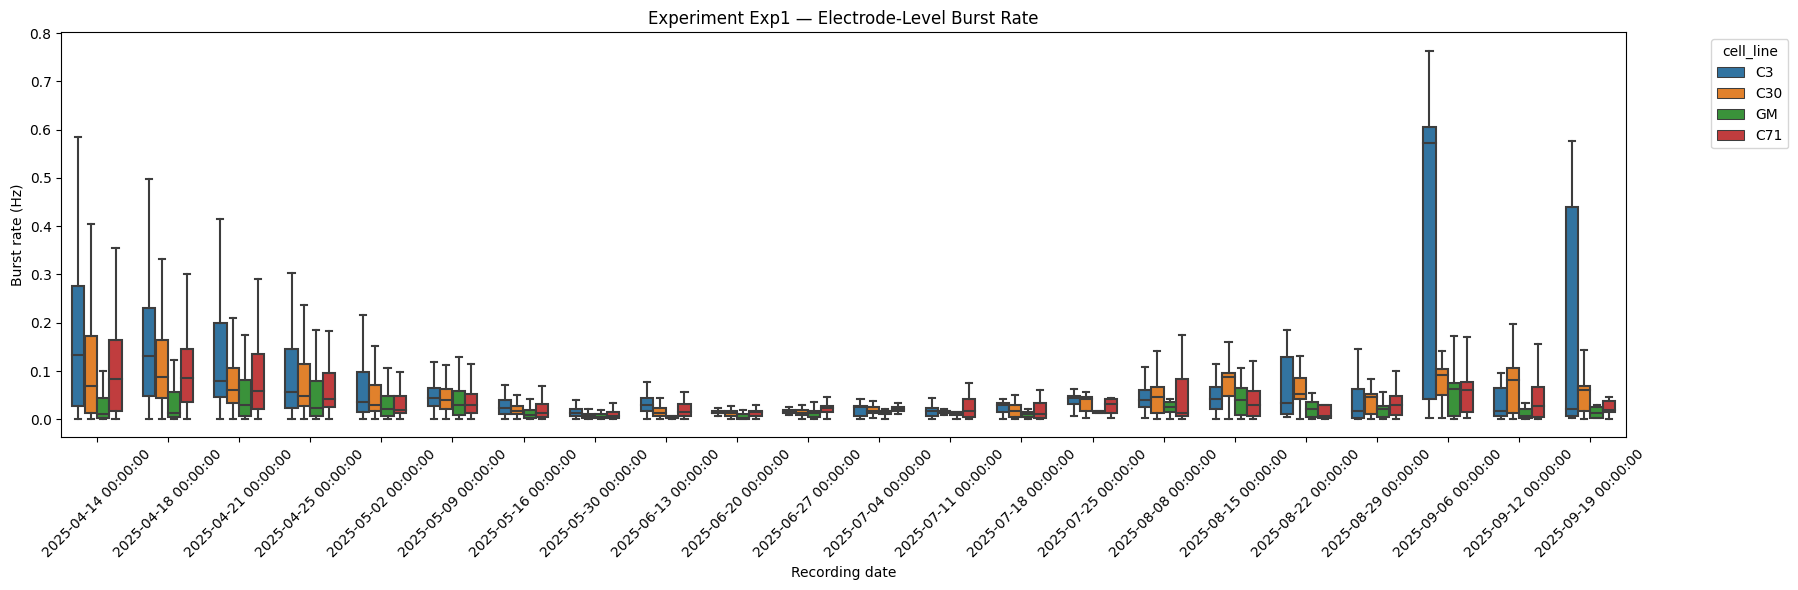

 → Plotting network (cell lines)

=== Plotting Experiment Exp1 ===


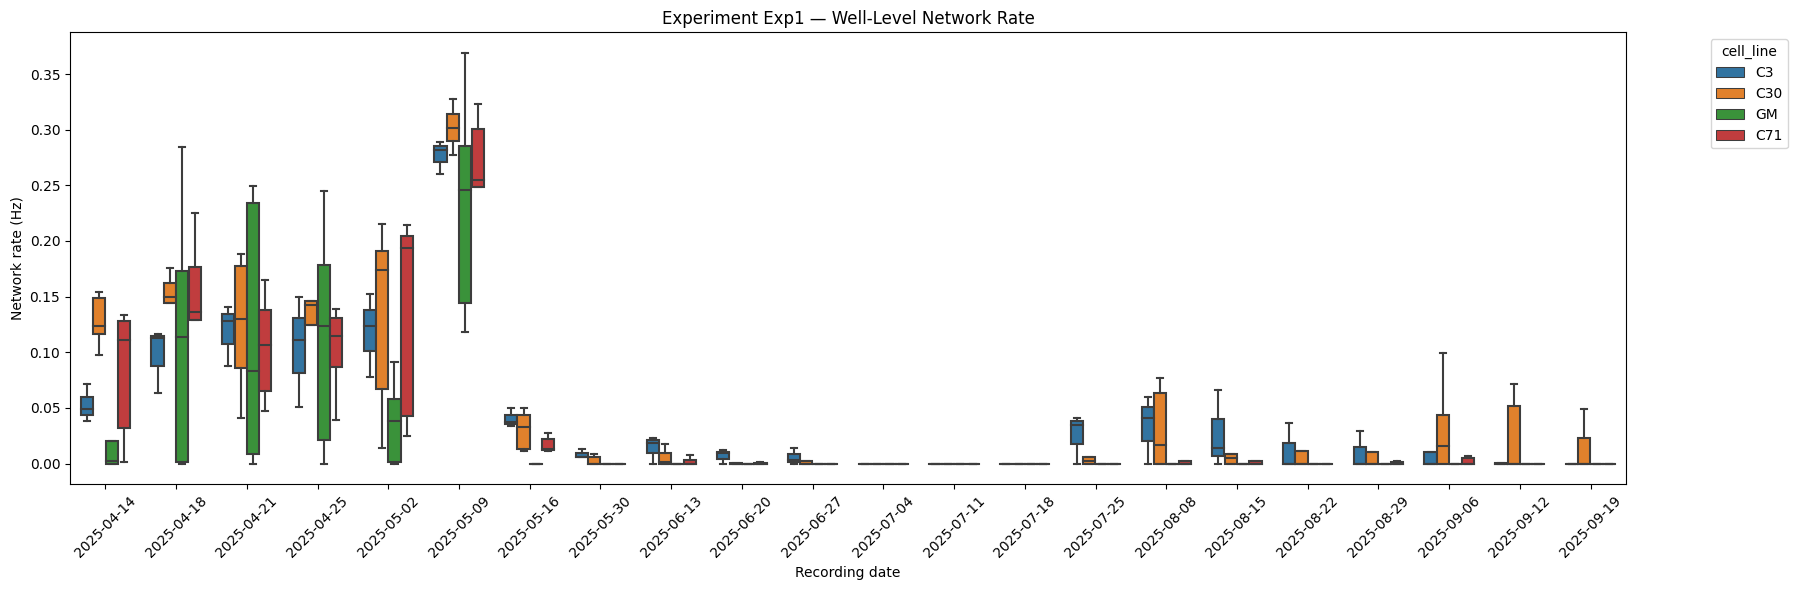

 → Plotting synchrony (cell lines)

=== Plotting Experiment Exp1 ===


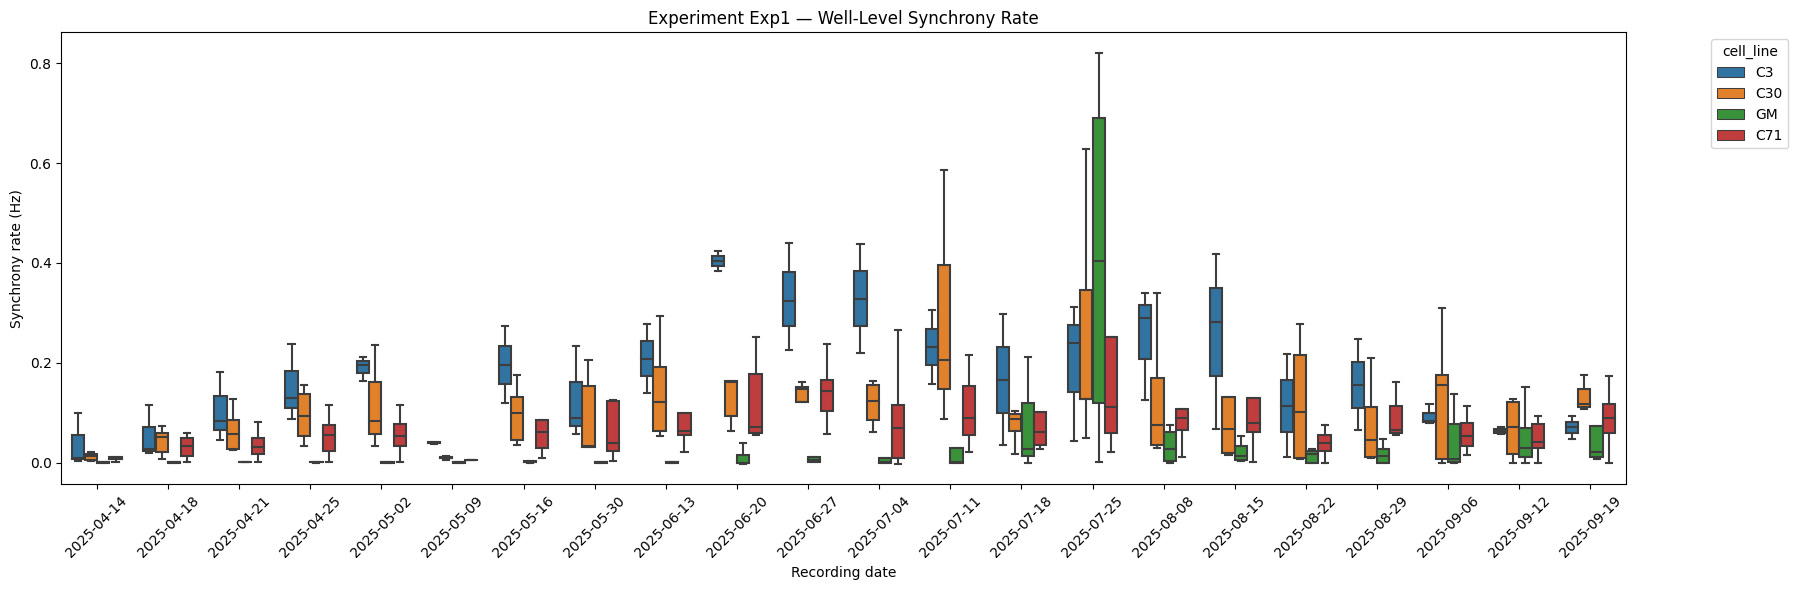


### GENERATING FEATURE PLOTS — GROUPS ###
 → Plotting firing (groups)

=== Plotting Experiment Exp1 ===


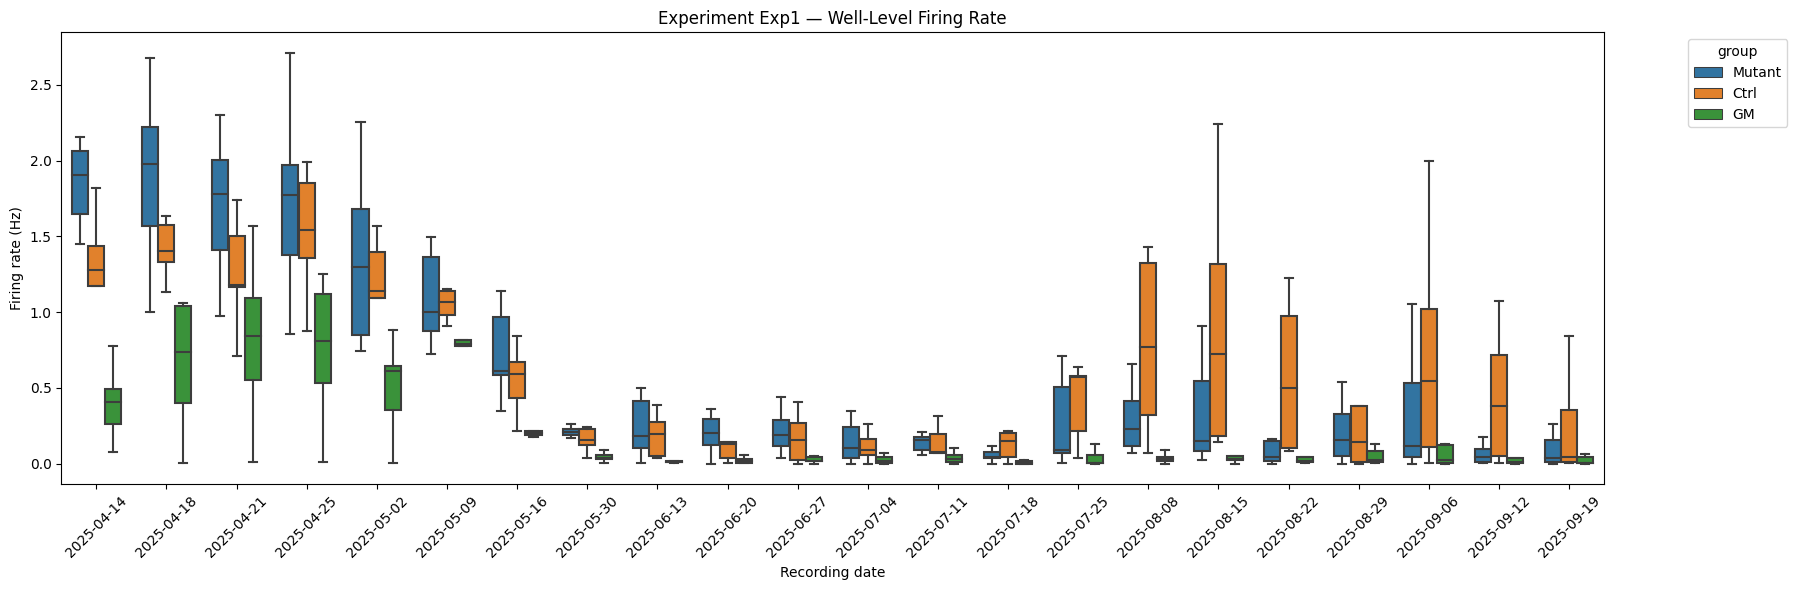

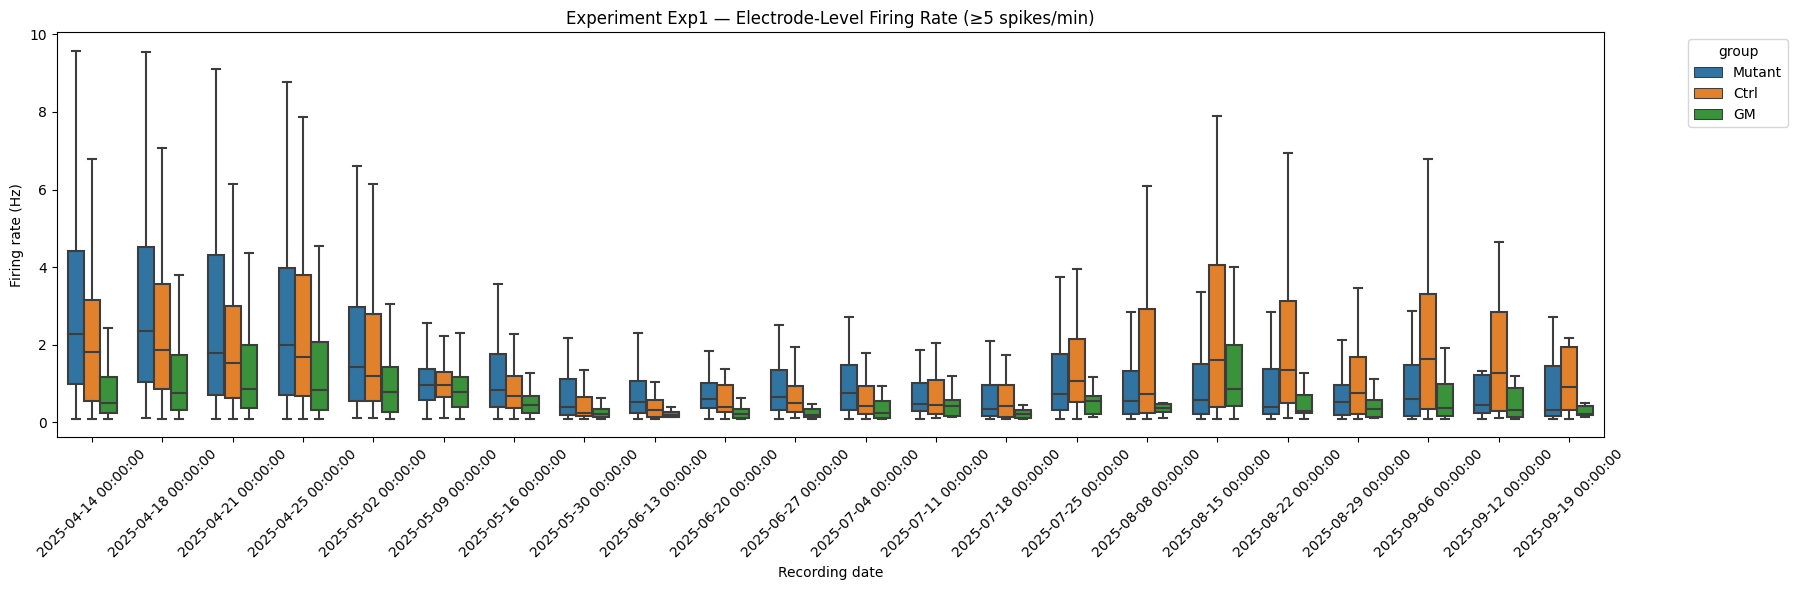

 → Plotting burst (groups)

=== Plotting Experiment Exp1 ===


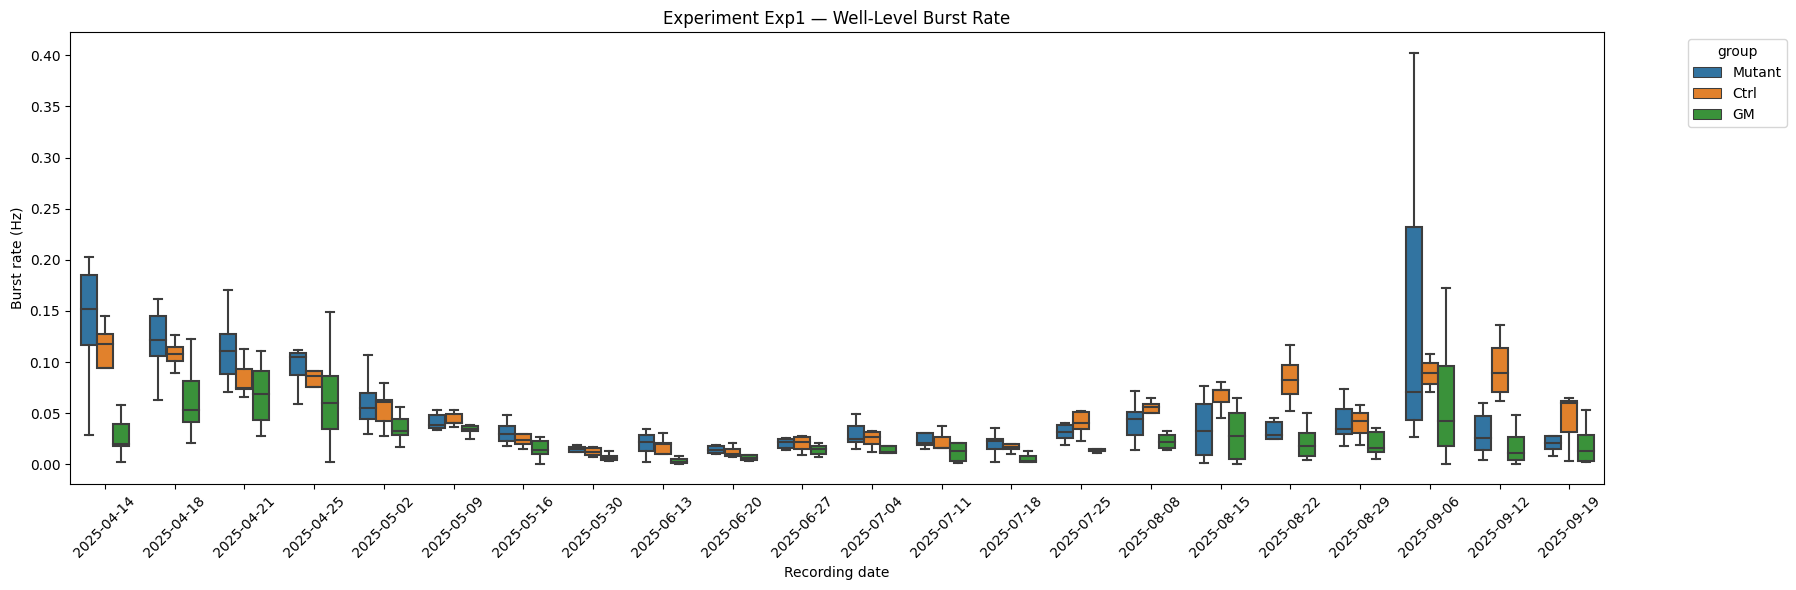

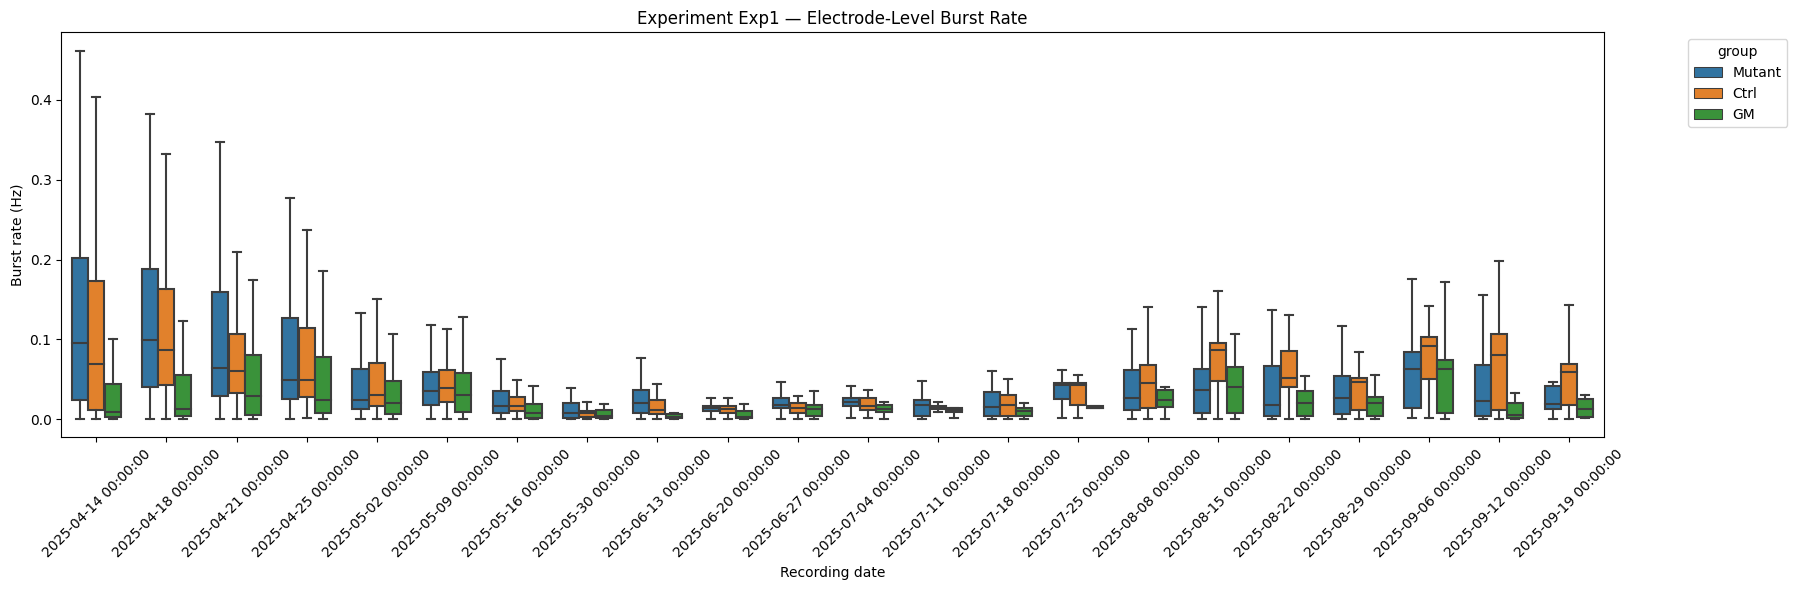

 → Plotting network (groups)

=== Plotting Experiment Exp1 ===


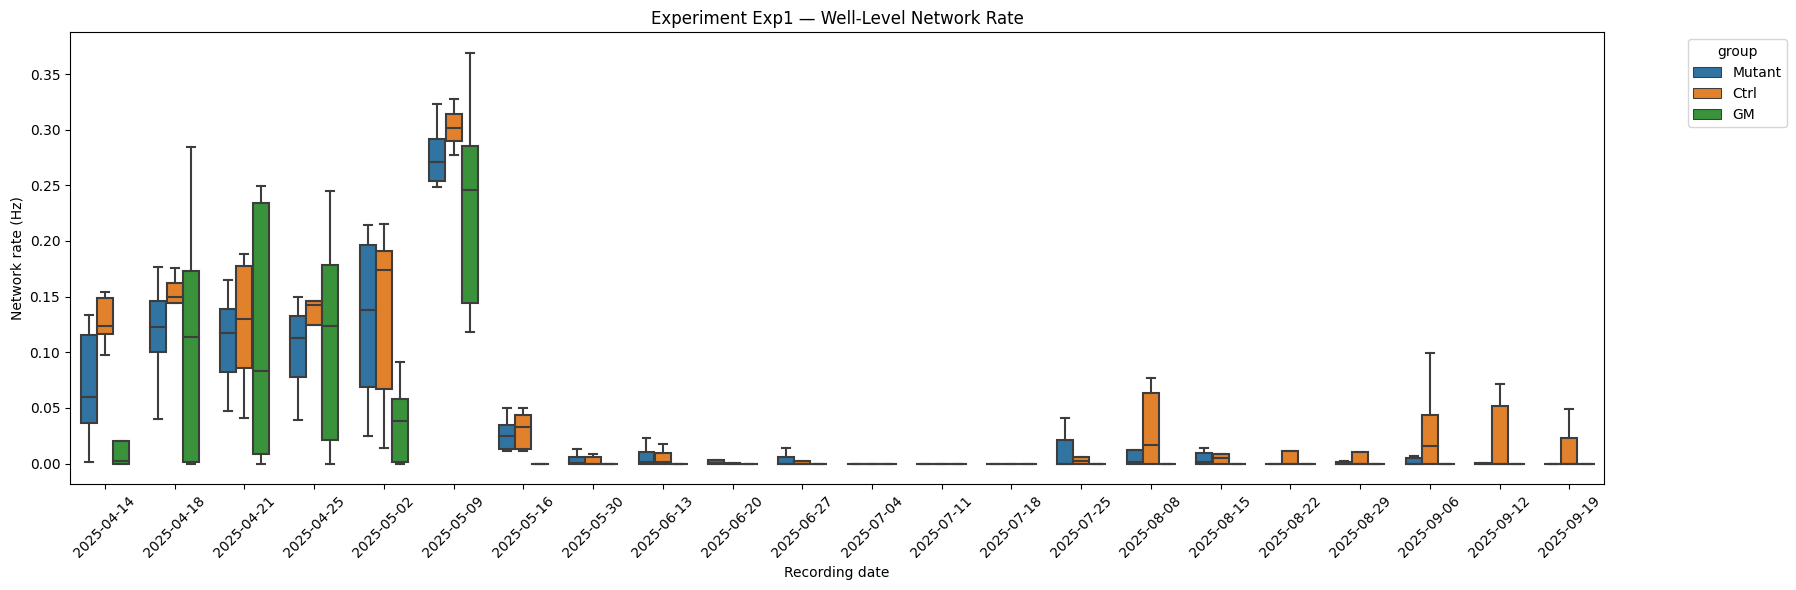

 → Plotting synchrony (groups)

=== Plotting Experiment Exp1 ===


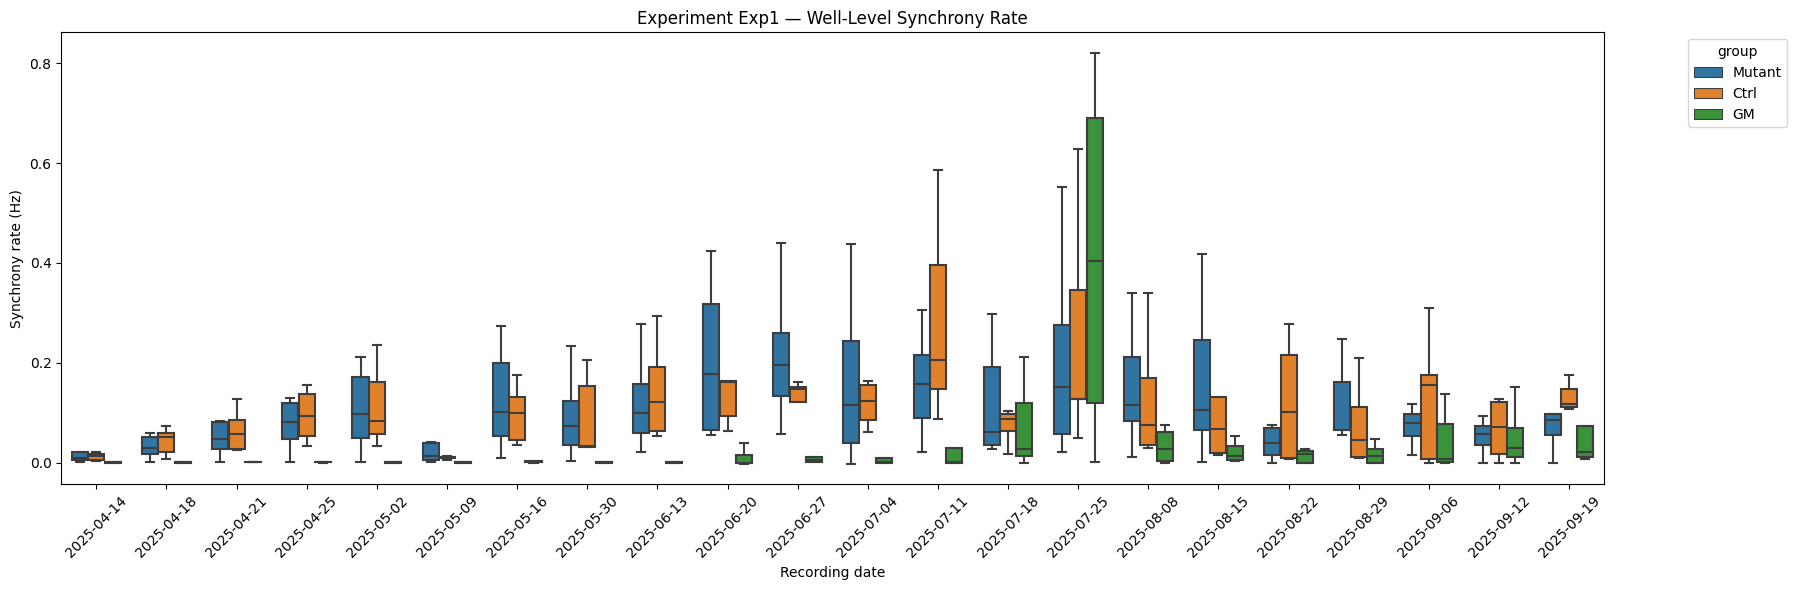


### RUNNING STATISTICS — CELL LINES ###

===== CELL LINE STATS: FIRING =====

  WELL-LEVEL POST-HOC t-tests:
  group1 group2     mean1     mean2  difference         t         p_raw  \
0     C3    C30  0.834810  0.630246    0.204564  1.566560  1.205079e-01   
1     C3    C71  0.834810  0.510883    0.323927  2.490020  1.451453e-02   
2     C3     GM  0.834810  0.217871    0.616939  5.145178  2.304483e-06   
3    C30    C71  0.630246  0.510883    0.119363  1.494901  1.364139e-01   
4    C30     GM  0.630246  0.217871    0.412375  6.663723  5.104112e-10   
5    C71     GM  0.510883  0.217871    0.293012  4.816112  3.593420e-06   

      p_fmt        p_bonf p_bonf_fmt  
0  0.120508  7.230472e-01   0.723047  
1  0.014515  8.708718e-02   0.087087  
2  0.000002  1.382690e-05   0.000014  
3  0.136414  8.184834e-01   0.818483  
4  0.000000  3.062467e-09   0.000000  
5  0.000004  2.156052e-05   0.000022  

===== CELL LINE STATS: BURST =====

  WELL-LEVEL POST-HOC t-tests:
  group1 group2     mea

In [31]:
results_exp1 = run_full_mea_analysis(
    big_df,
    experiment='Exp1',
    assign_groups=True,
    use_group_for_plate_map=True,
    double_label=True
)


### Exp 2 analysis


### RUNNING ANALYSIS FOR Exp2 ###
Plates included: ['MAOA72' 'MAOA76' 'MAOA77']

### DRAWING PLATE MAPS ###
 → Plotting MAOA72


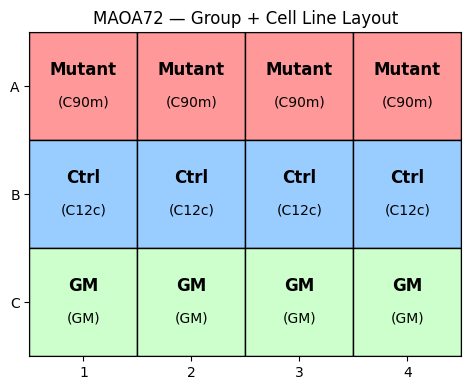

 → Plotting MAOA76


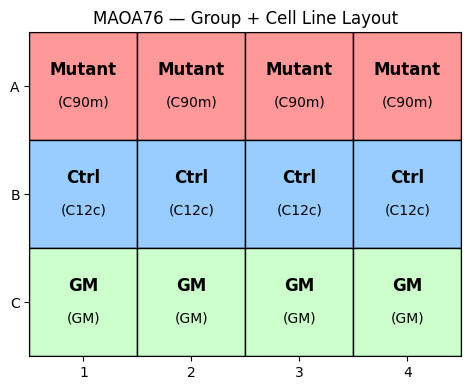

 → Plotting MAOA77


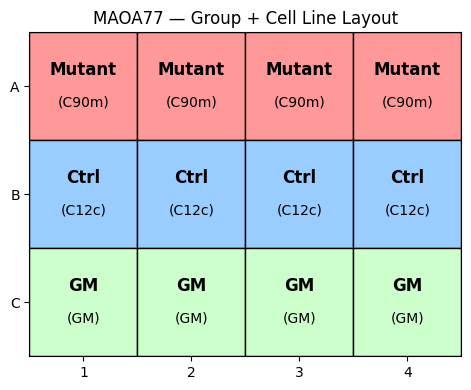


### GENERATING FEATURE PLOTS — CELL LINES ###
 → Plotting firing (cell lines)

=== Plotting Experiment Exp2 ===


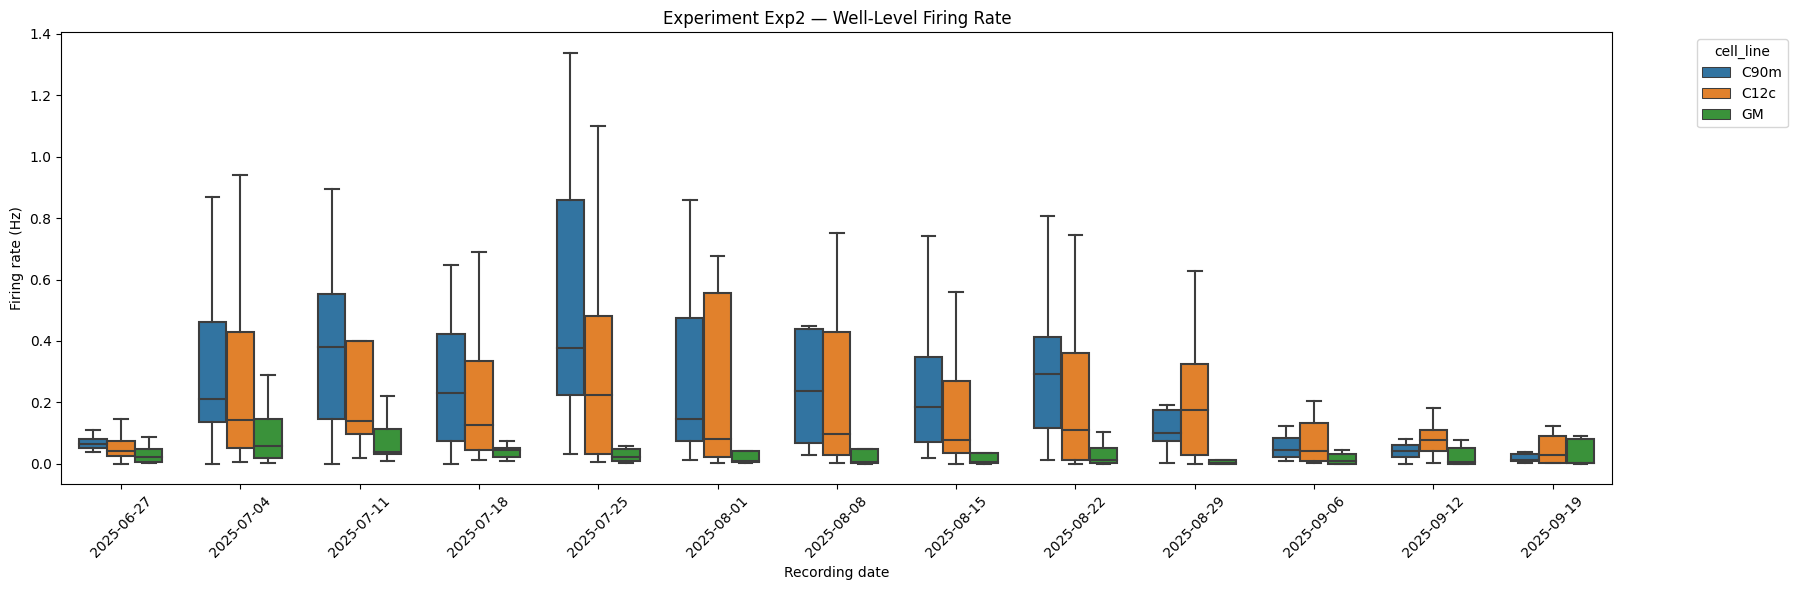

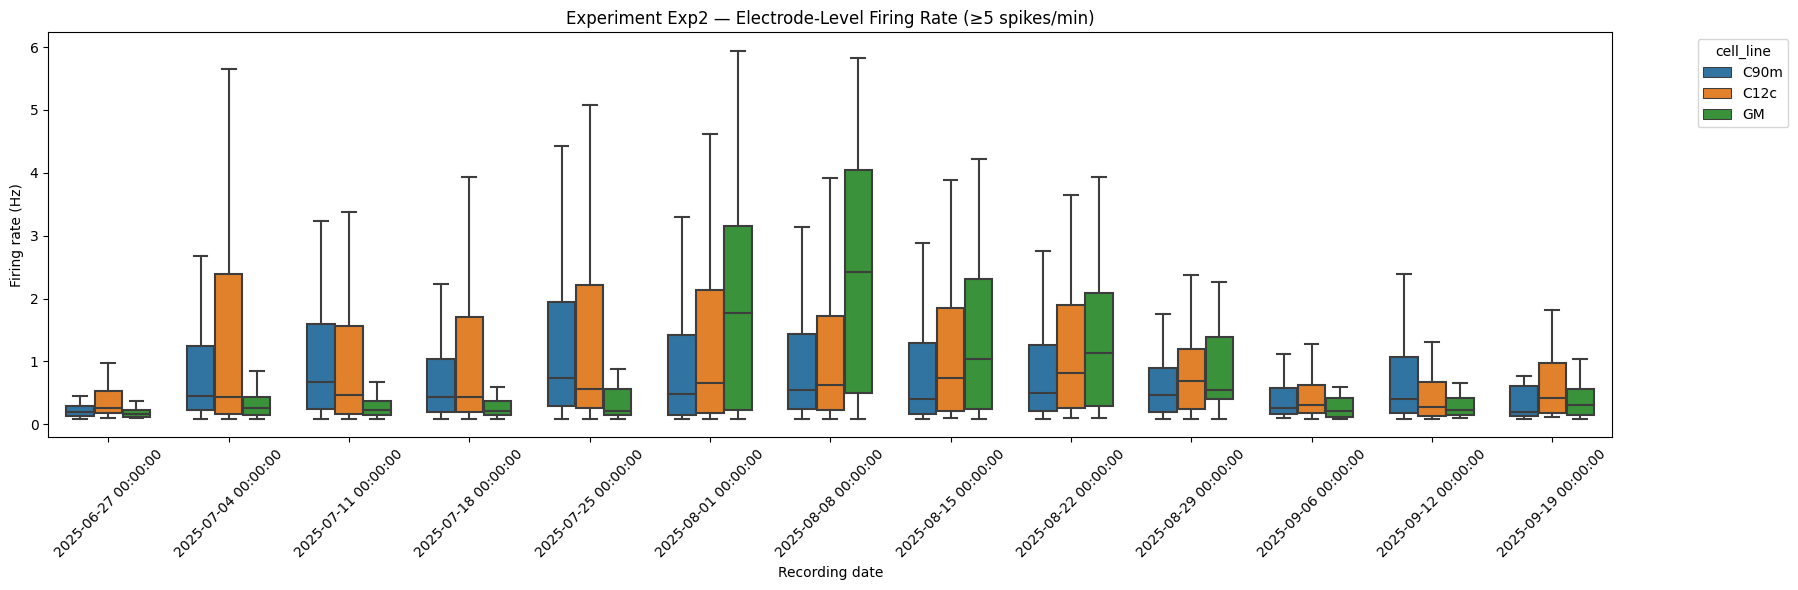

 → Plotting burst (cell lines)

=== Plotting Experiment Exp2 ===


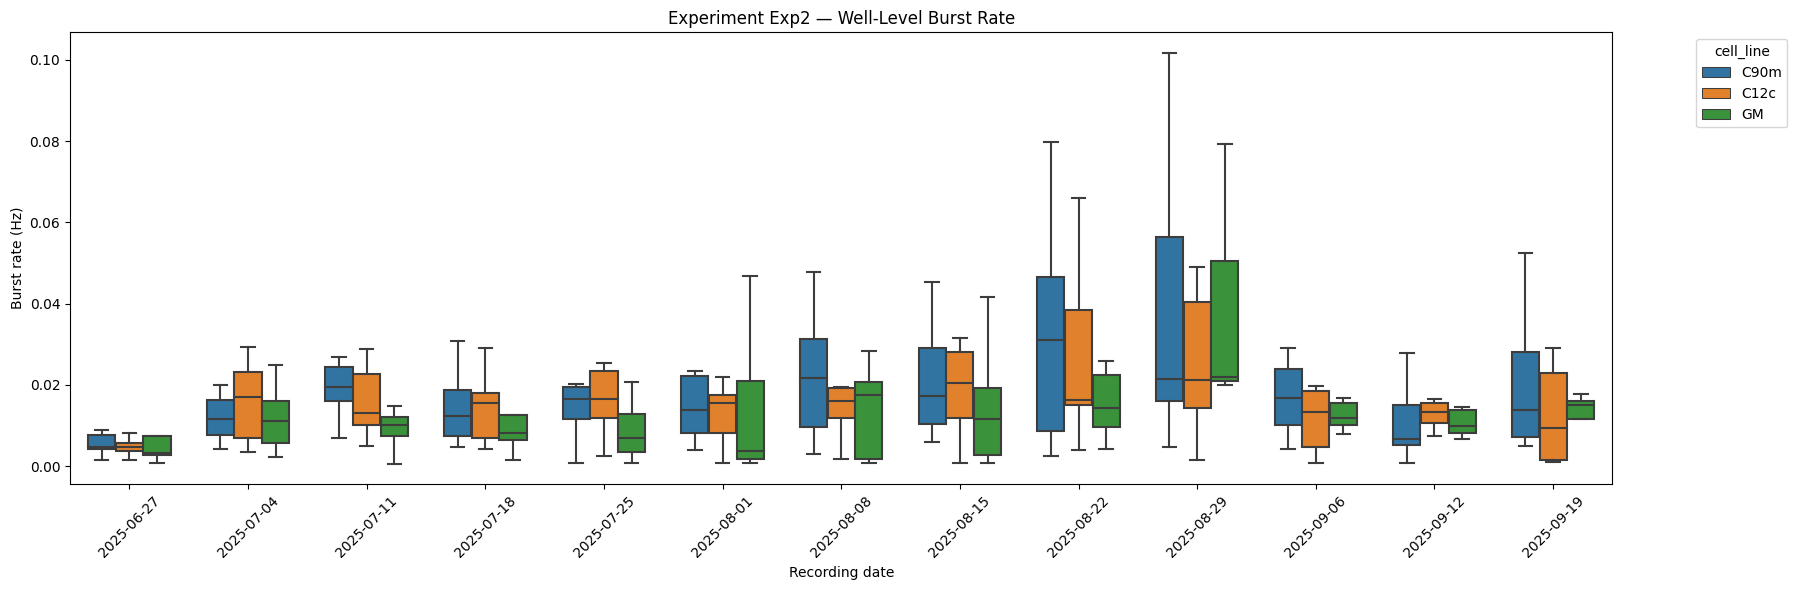

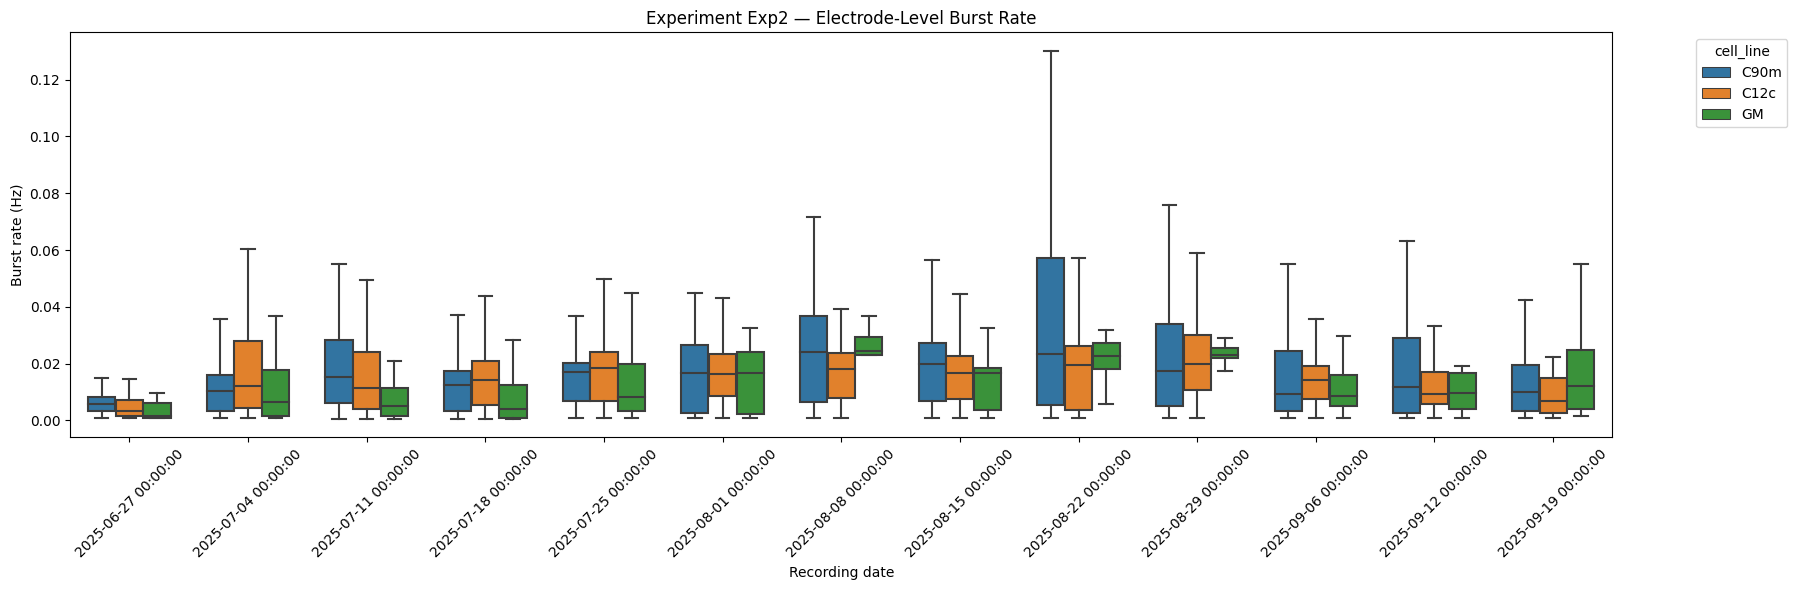

 → Plotting network (cell lines)

=== Plotting Experiment Exp2 ===


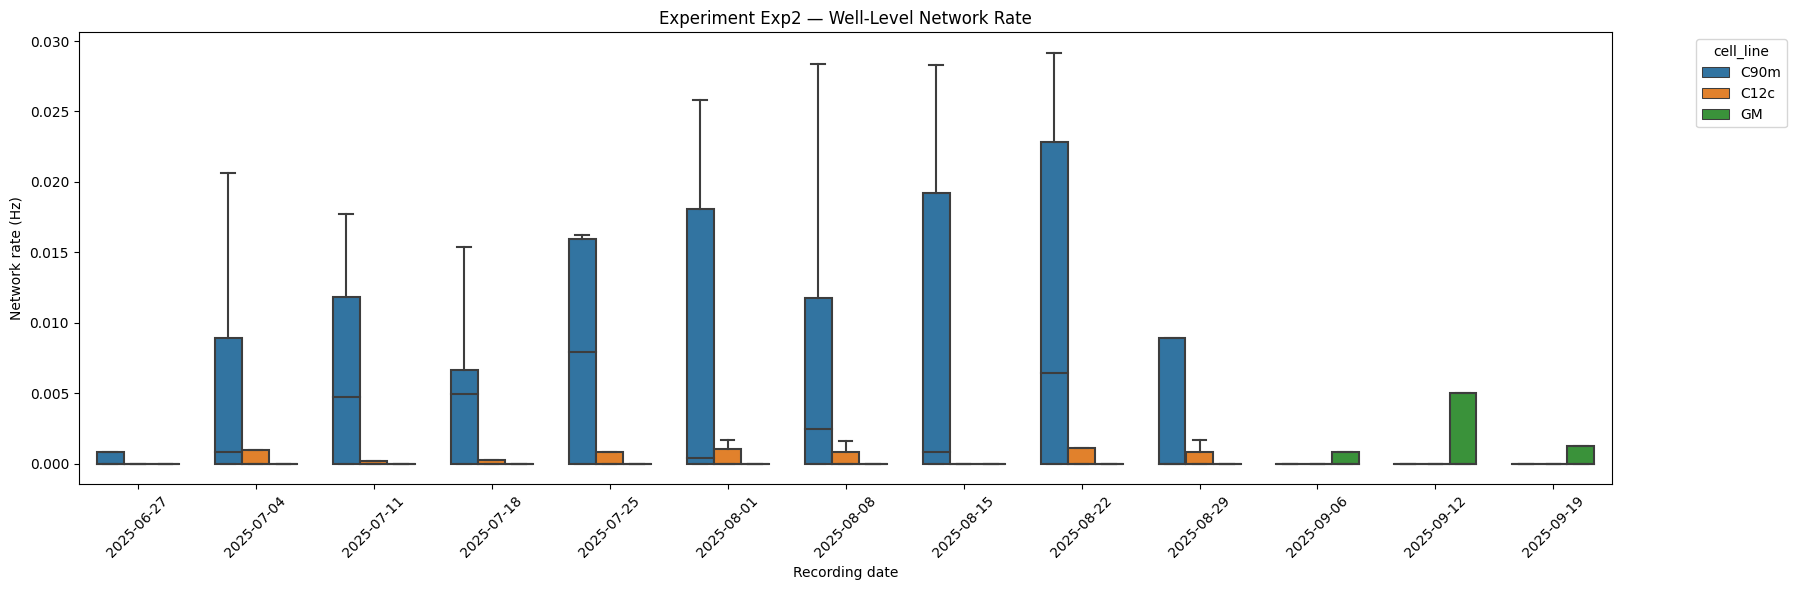

 → Plotting synchrony (cell lines)

=== Plotting Experiment Exp2 ===


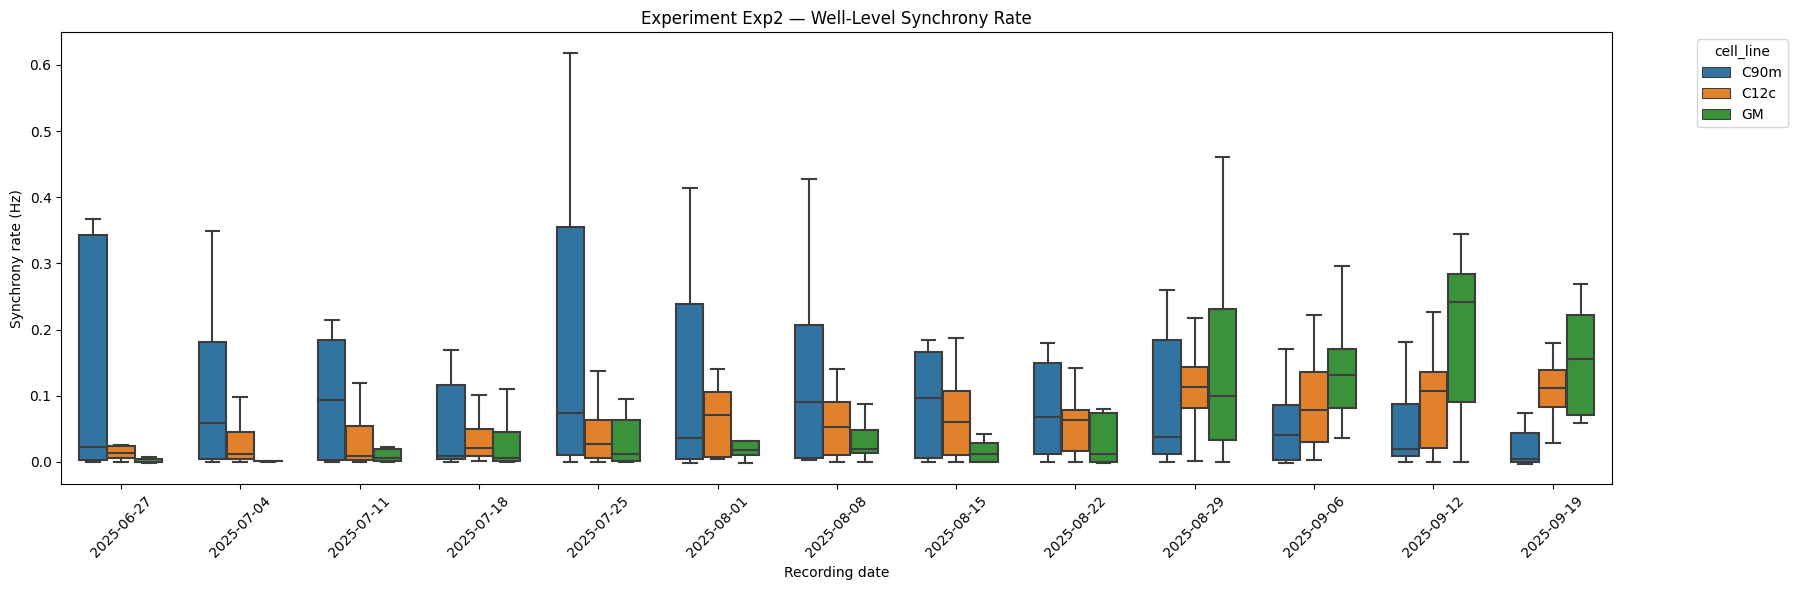


### GENERATING FEATURE PLOTS — GROUPS ###
 → Plotting firing (groups)

=== Plotting Experiment Exp2 ===


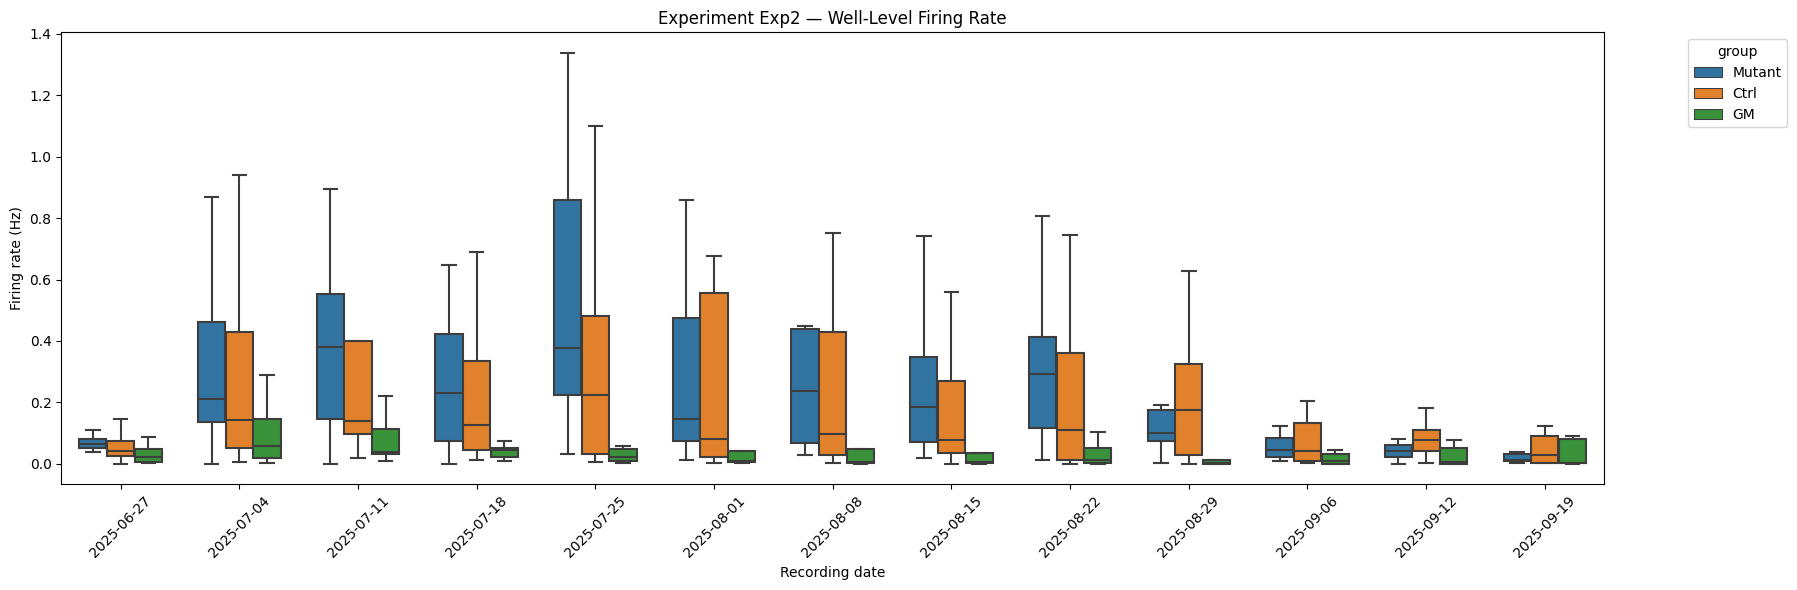

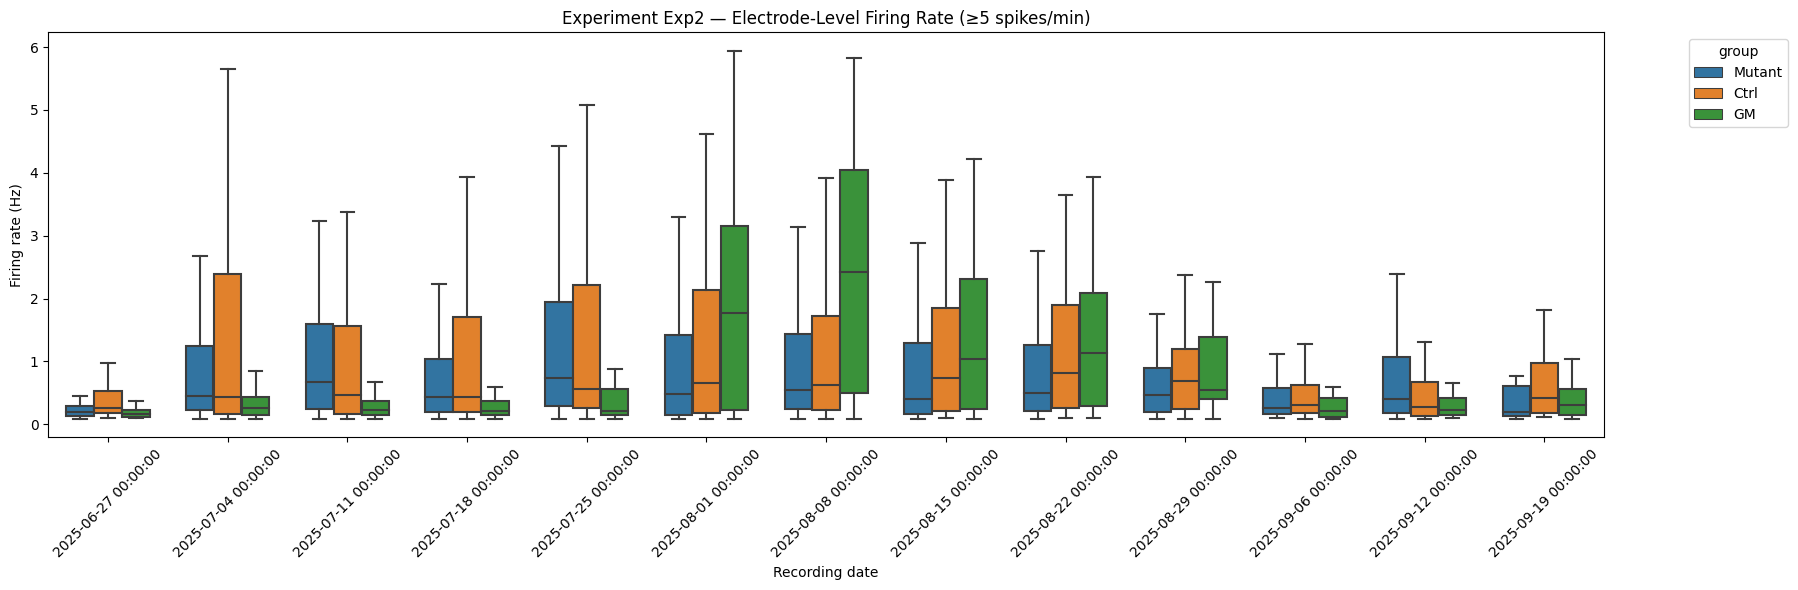

 → Plotting burst (groups)

=== Plotting Experiment Exp2 ===


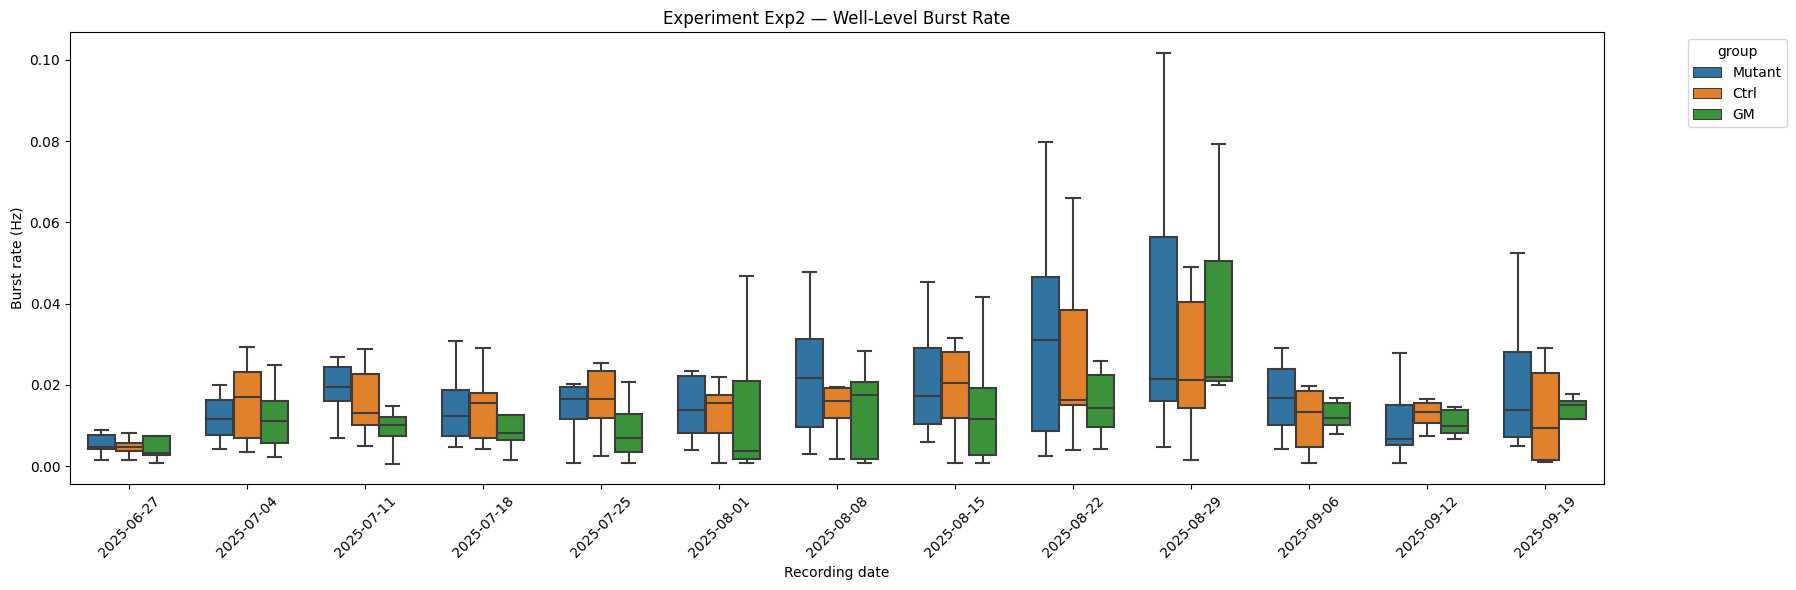

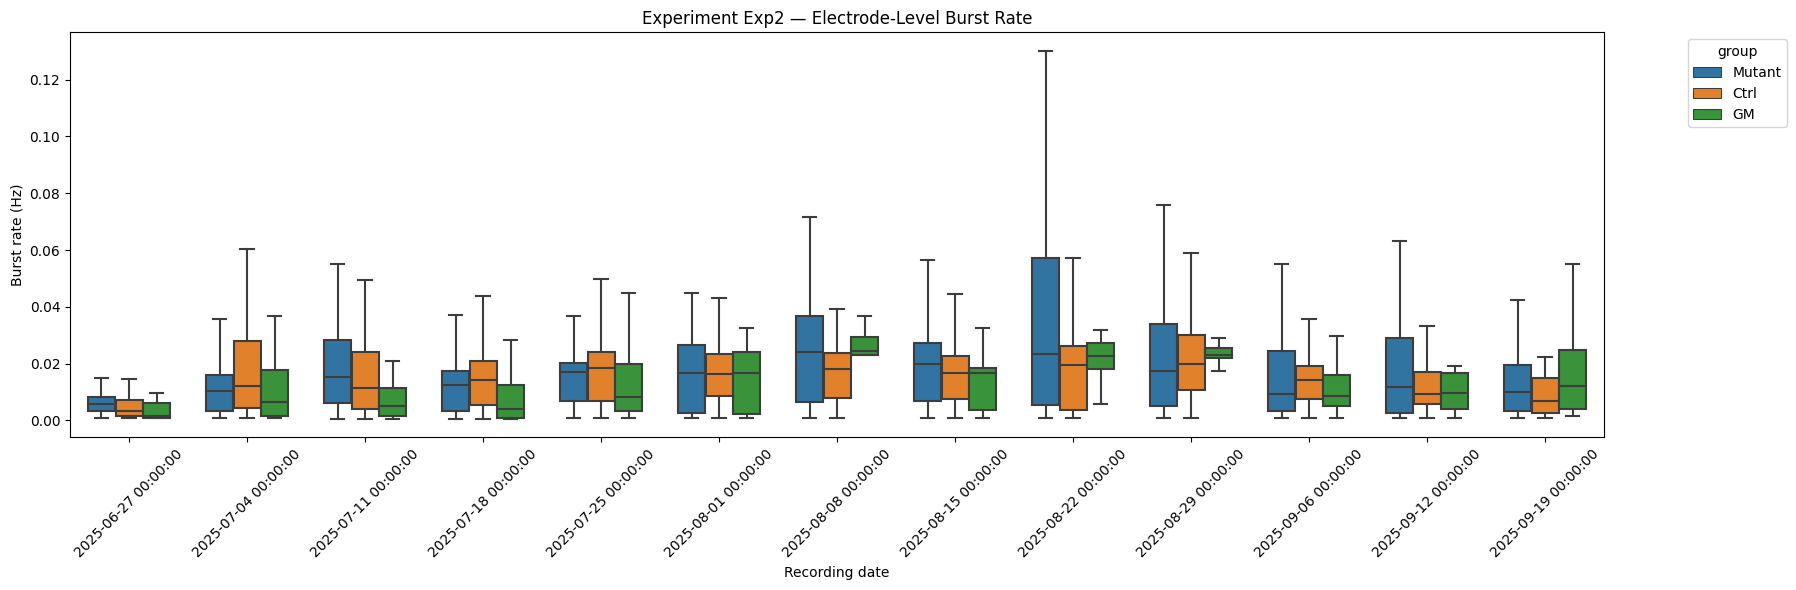

 → Plotting network (groups)

=== Plotting Experiment Exp2 ===


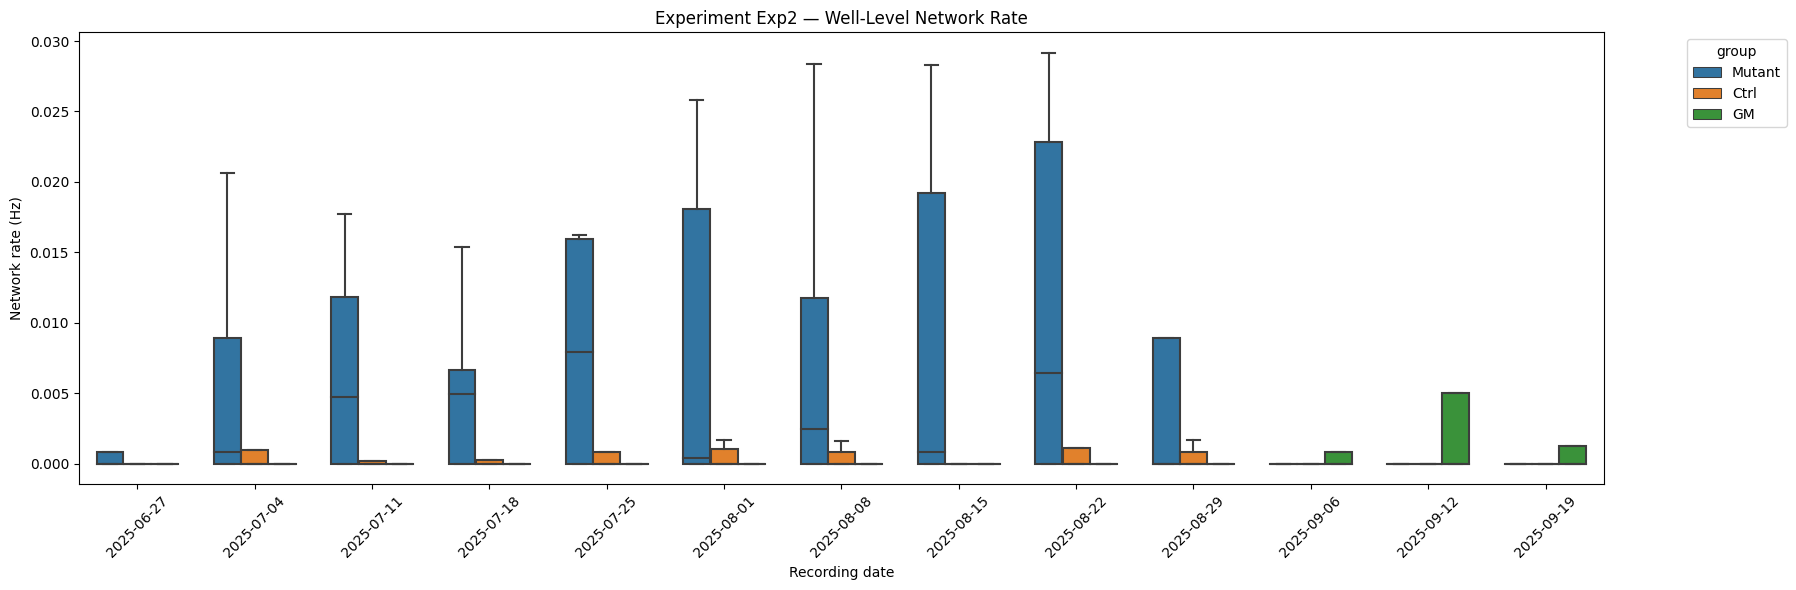

 → Plotting synchrony (groups)

=== Plotting Experiment Exp2 ===


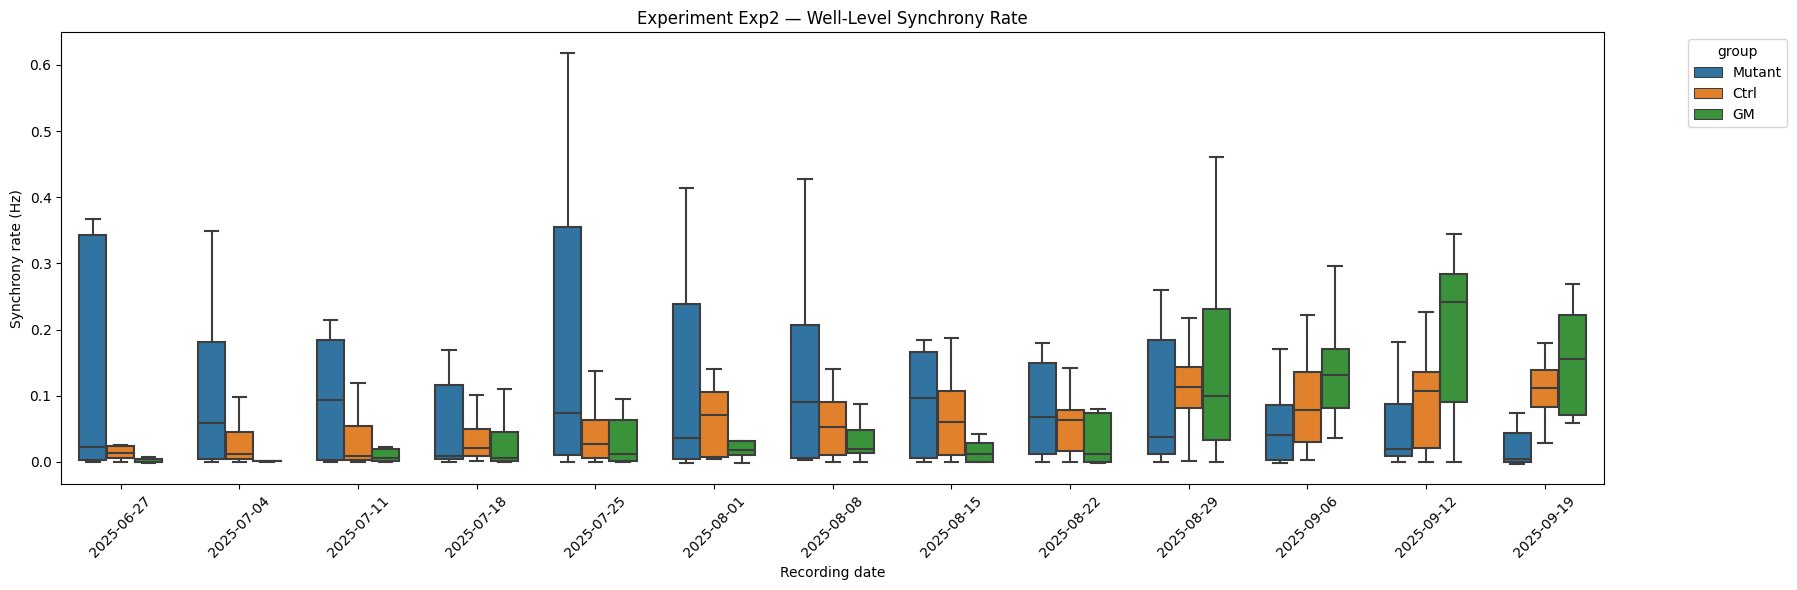


### RUNNING STATISTICS — CELL LINES ###

===== CELL LINE STATS: FIRING =====

  WELL-LEVEL POST-HOC t-tests:
  group1 group2     mean1     mean2  difference         t         p_raw  \
0   C12c   C90m  0.226548  0.290463   -0.063915 -1.505234  1.333815e-01   
1   C12c     GM  0.226548  0.085525    0.141023  4.626850  6.252801e-06   
2   C90m     GM  0.290463  0.085525    0.204938  5.697193  4.264939e-08   

      p_fmt        p_bonf p_bonf_fmt  
0  0.133382  4.001446e-01   0.400145  
1  0.000006  1.875840e-05   0.000019  
2  0.000000  1.279482e-07   0.000000  

===== CELL LINE STATS: BURST =====

  WELL-LEVEL POST-HOC t-tests:
  group1 group2     mean1     mean2  difference         t     p_raw     p_fmt  \
0   C12c   C90m  0.017181  0.021117   -0.003936 -1.863236  0.063680  0.063680   
1   C12c     GM  0.017181  0.013416    0.003765  2.065371  0.040156  0.040156   
2   C90m     GM  0.021117  0.013416    0.007701  3.471390  0.000621  0.000621   

     p_bonf p_bonf_fmt  
0  0.191041   0

In [32]:
results_exp1 = run_full_mea_analysis(
    big_df,
    experiment='Exp2',
    assign_groups=True,
    use_group_for_plate_map=True,
    double_label=True
)


### Exp 3 analysis 


### RUNNING ANALYSIS FOR Exp3 ###
Plates included: ['MAOA72' 'MAOA77' 'MAOA76']

### DRAWING PLATE MAPS ###
 → Plotting MAOA72


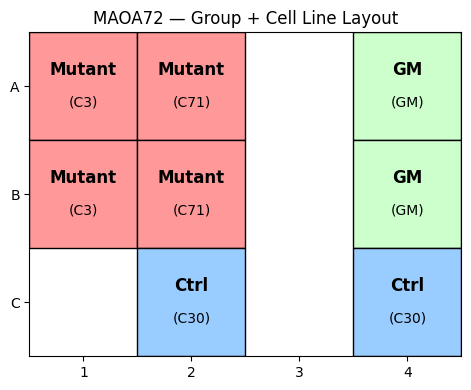

 → Plotting MAOA77


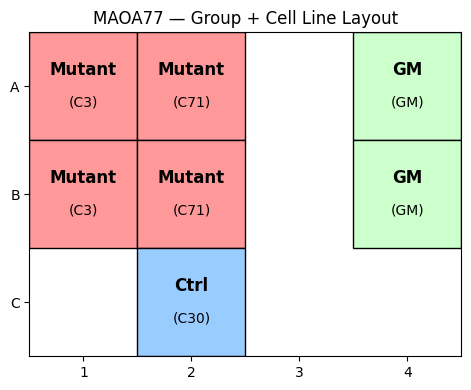

 → Plotting MAOA76


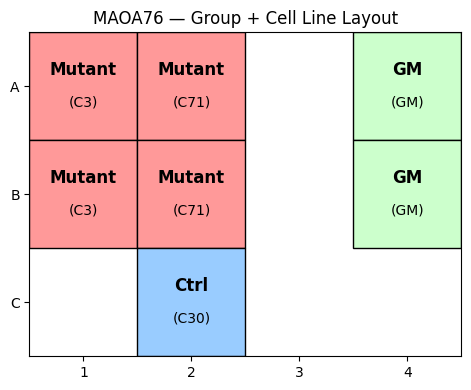


### GENERATING FEATURE PLOTS — CELL LINES ###
 → Plotting firing (cell lines)

=== Plotting Experiment Exp3 ===


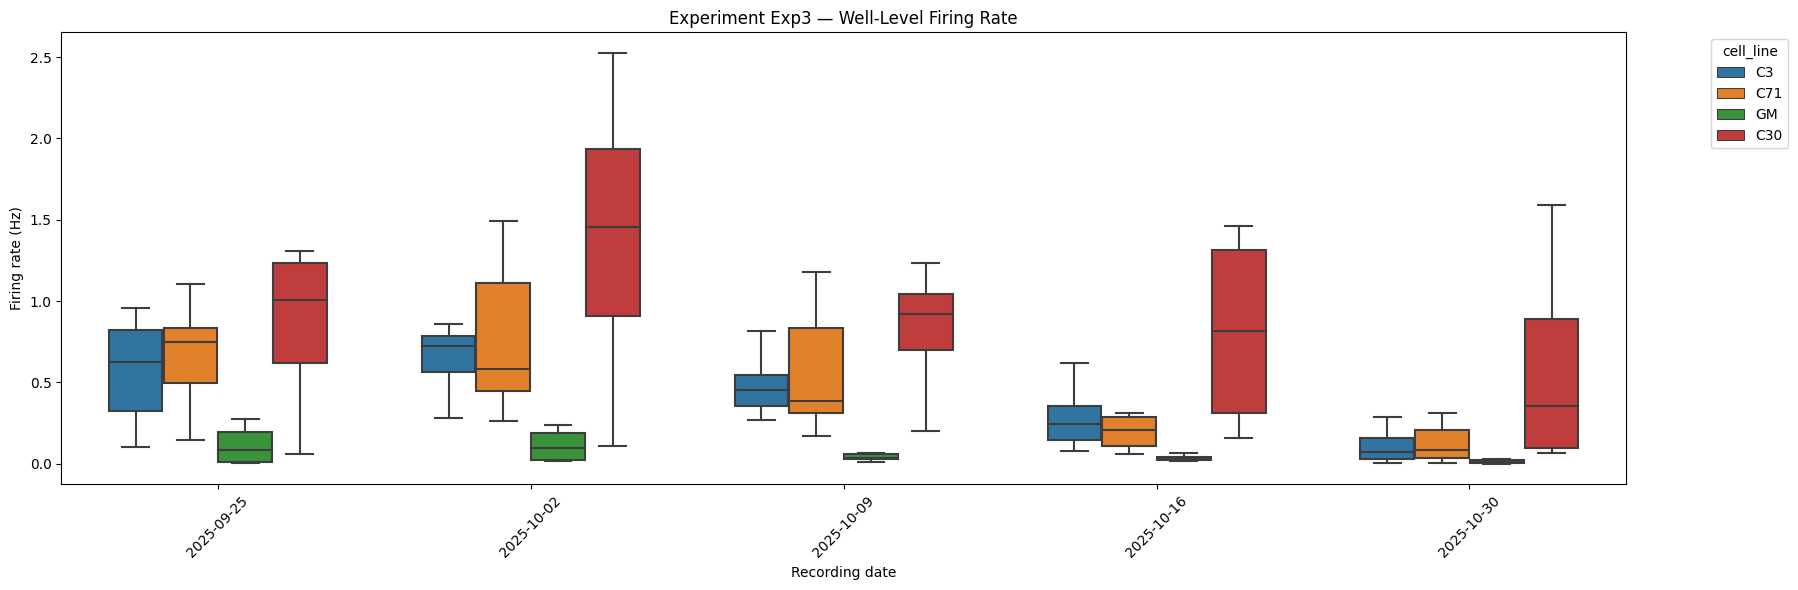

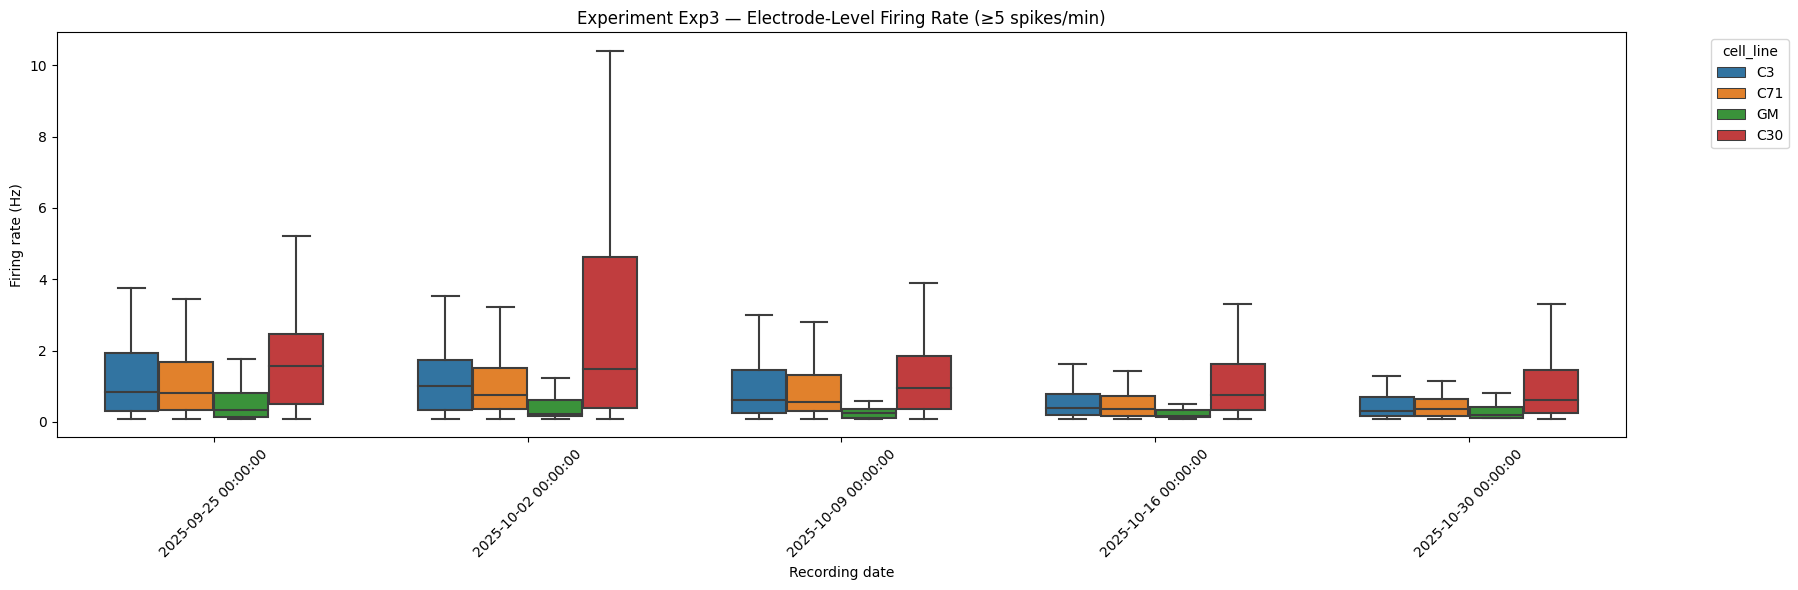

 → Plotting burst (cell lines)

=== Plotting Experiment Exp3 ===


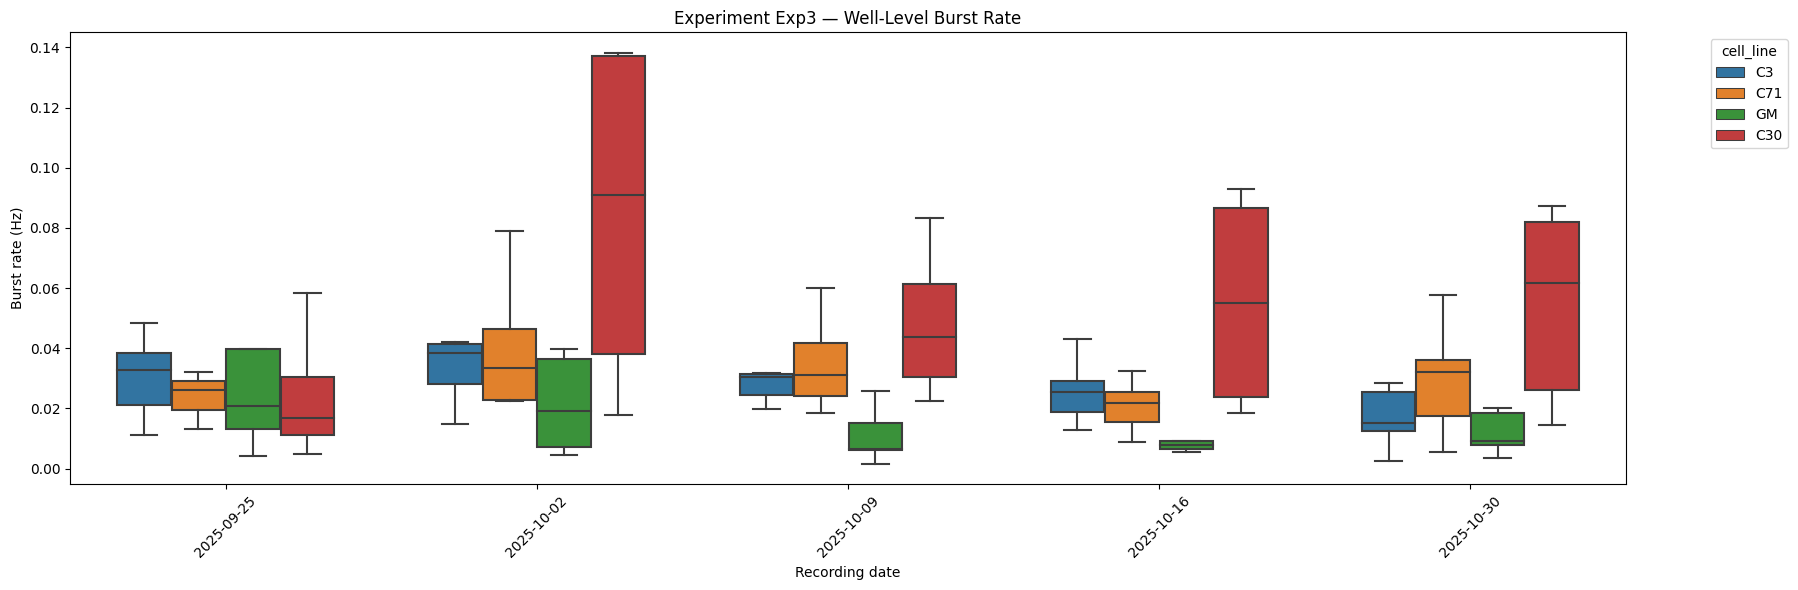

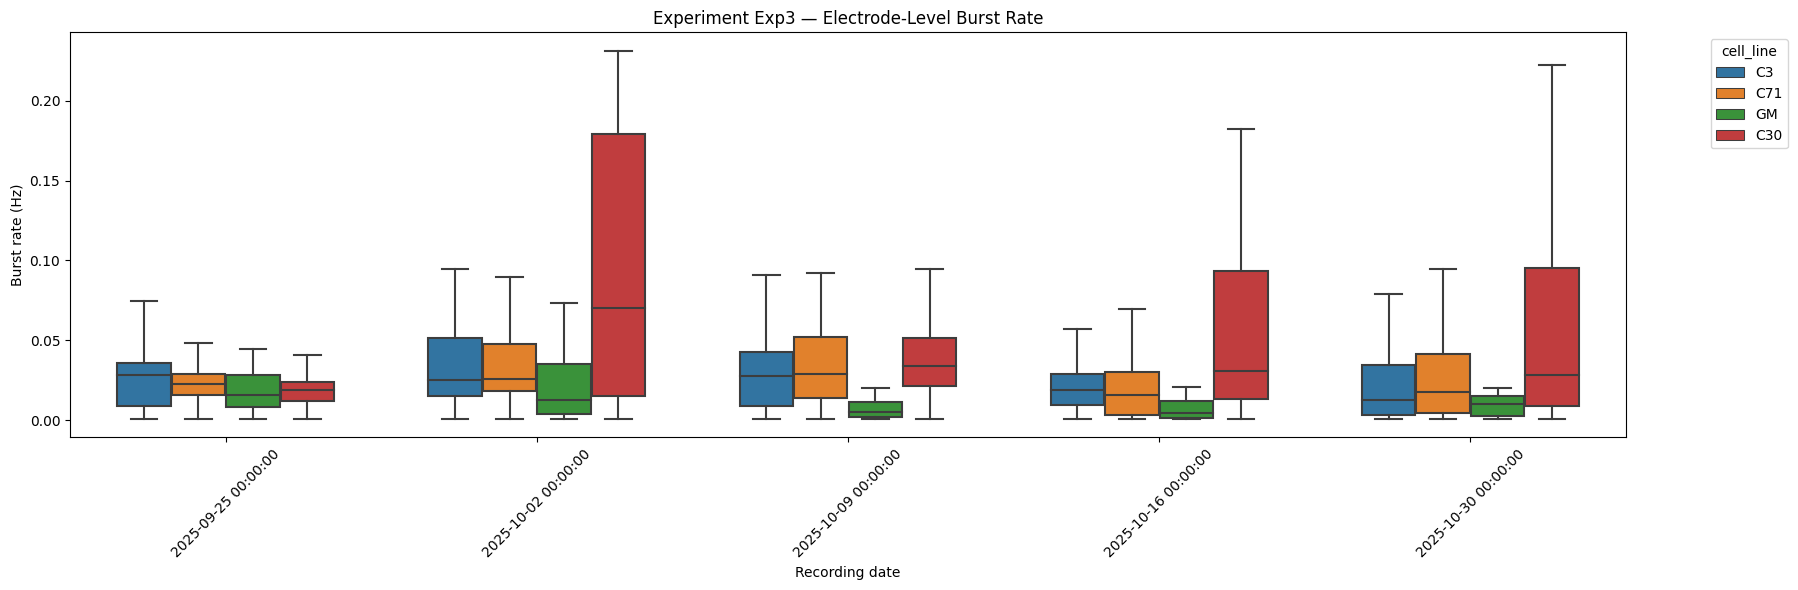

 → Plotting network (cell lines)

=== Plotting Experiment Exp3 ===


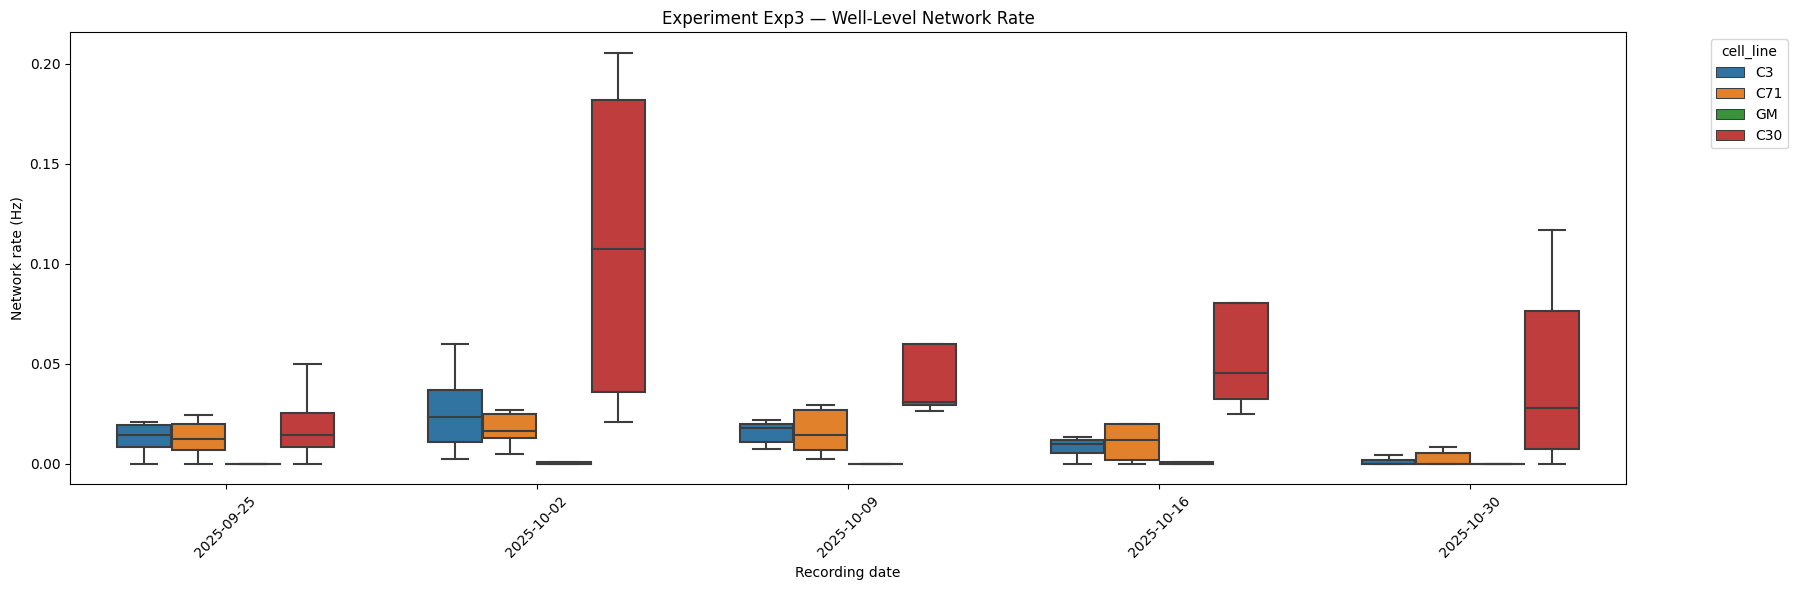

 → Plotting synchrony (cell lines)

=== Plotting Experiment Exp3 ===


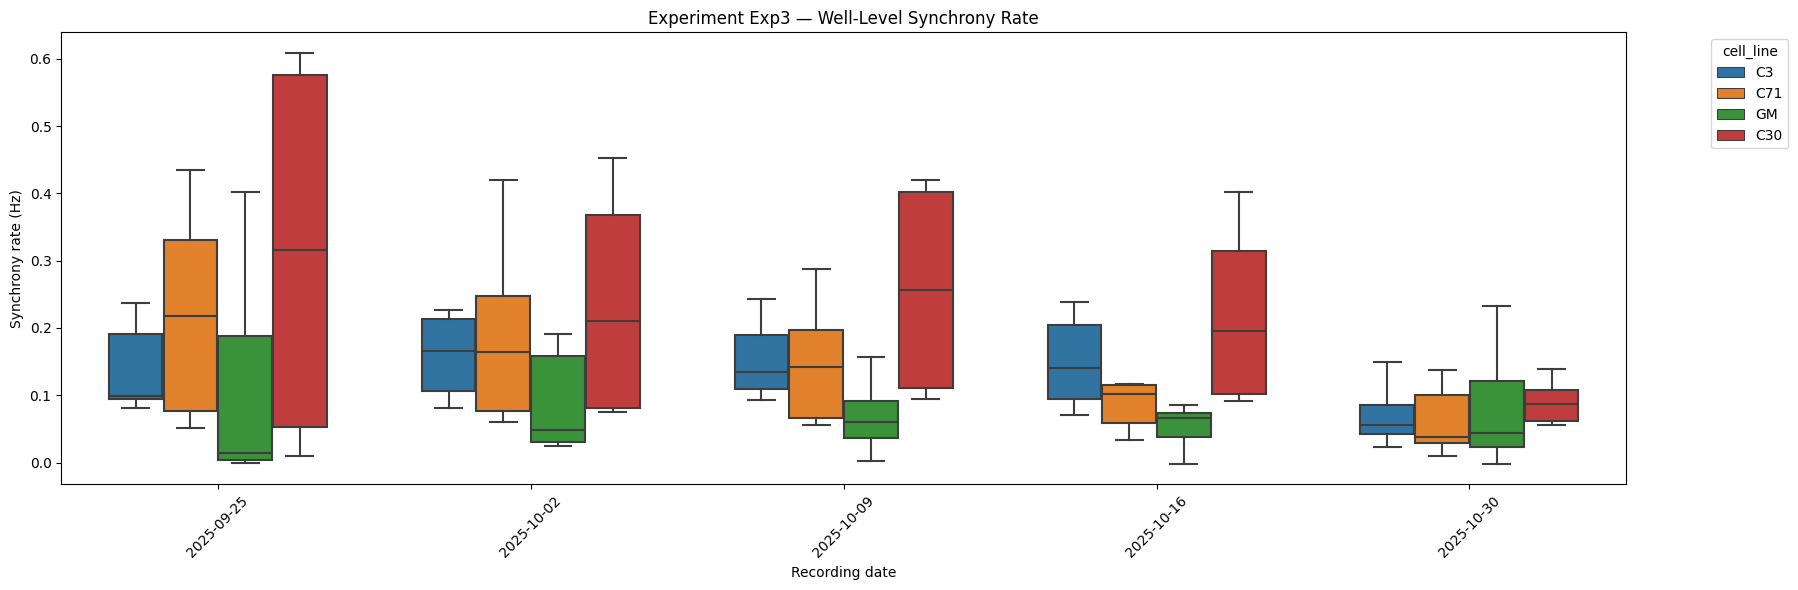


### GENERATING FEATURE PLOTS — GROUPS ###
 → Plotting firing (groups)

=== Plotting Experiment Exp3 ===


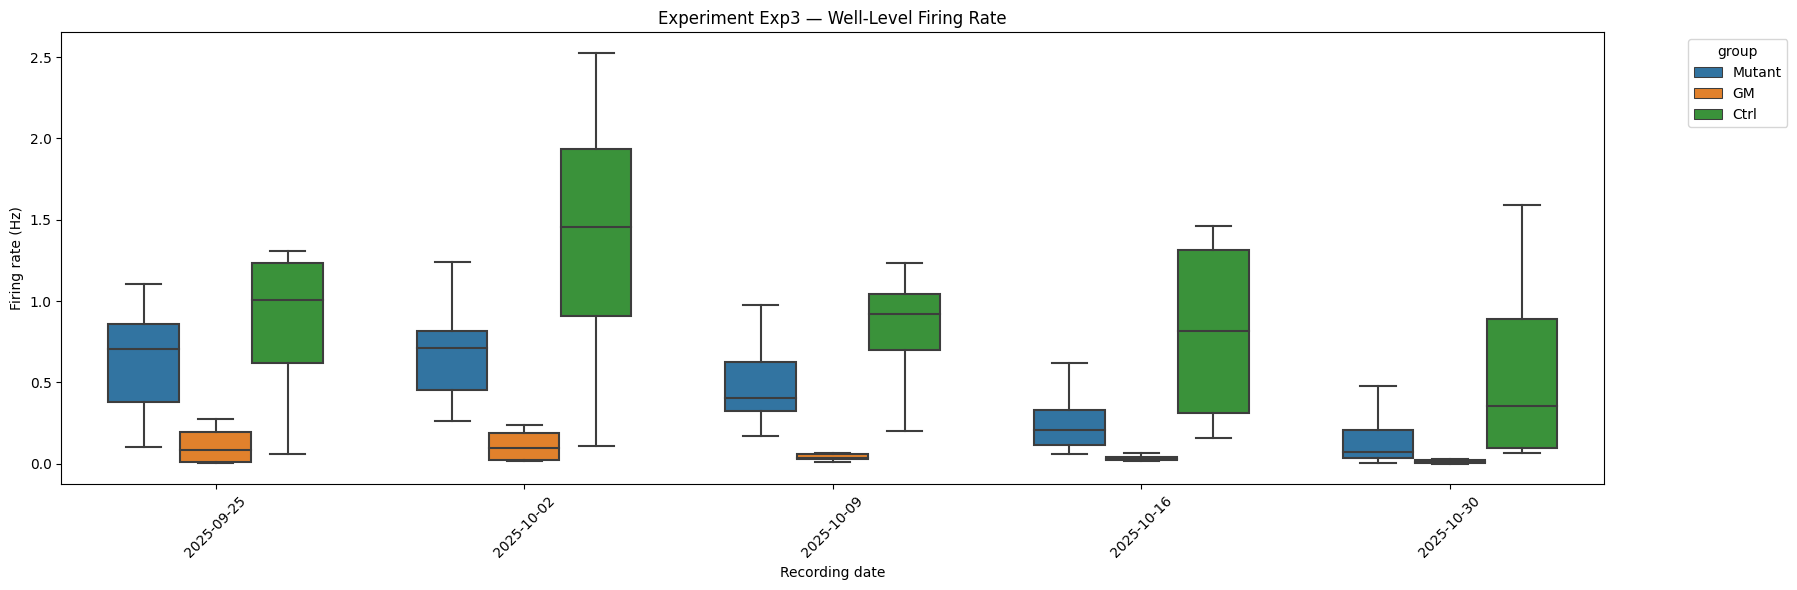

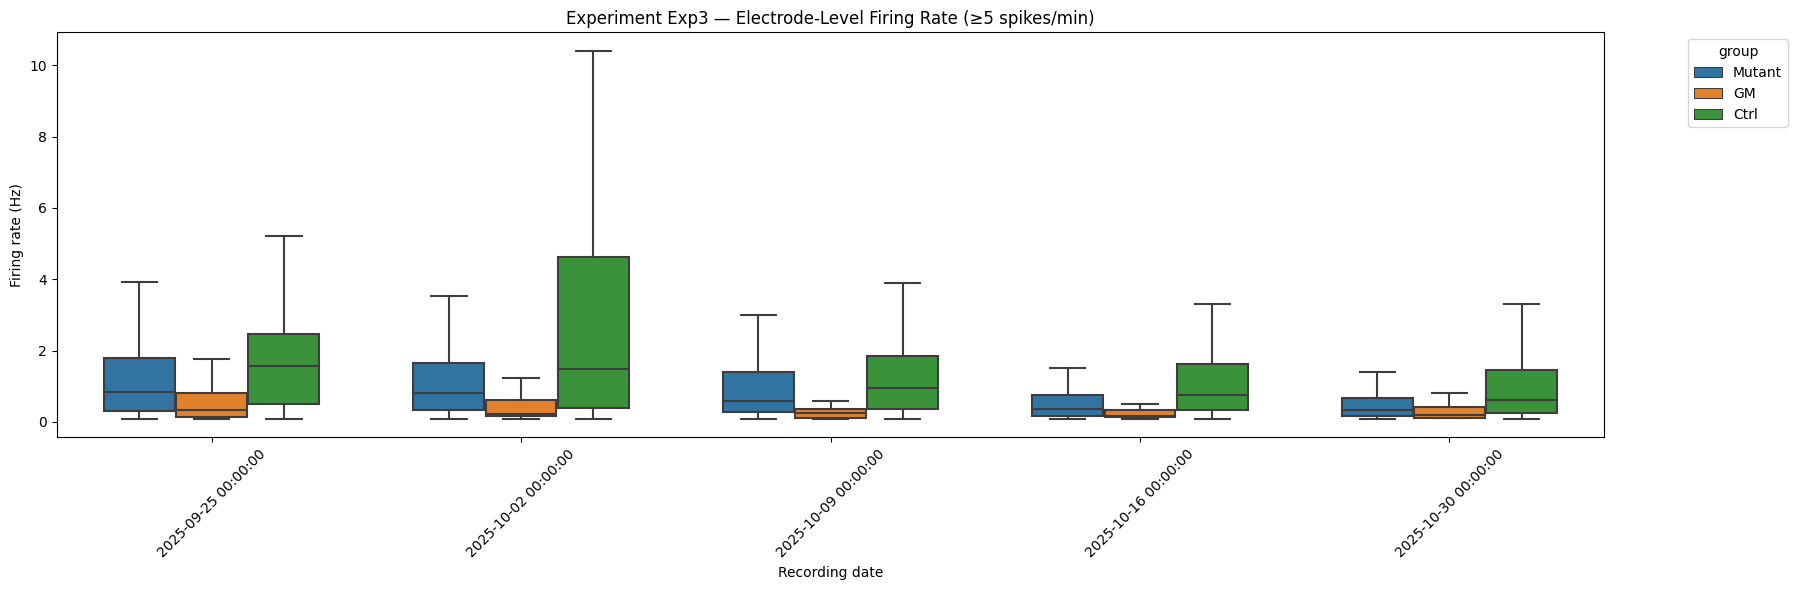

 → Plotting burst (groups)

=== Plotting Experiment Exp3 ===


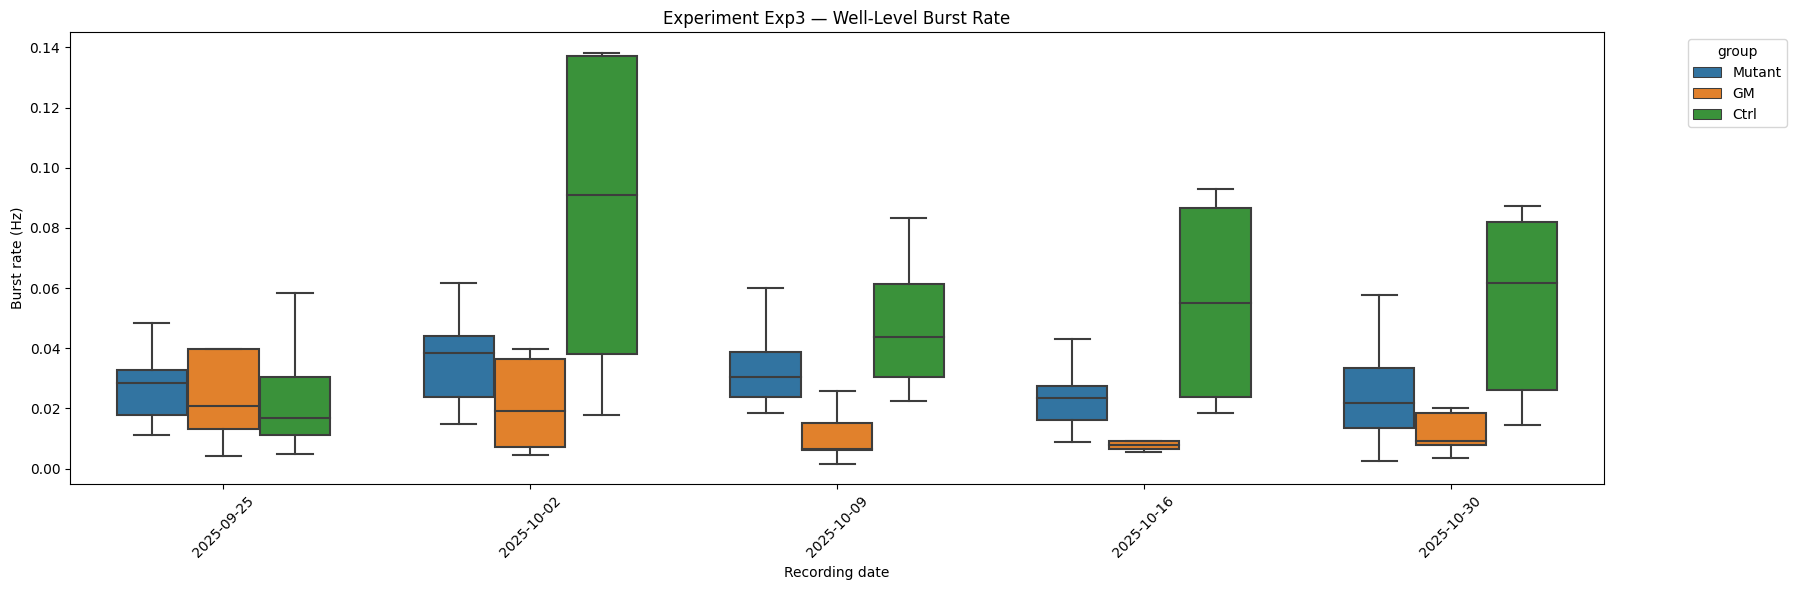

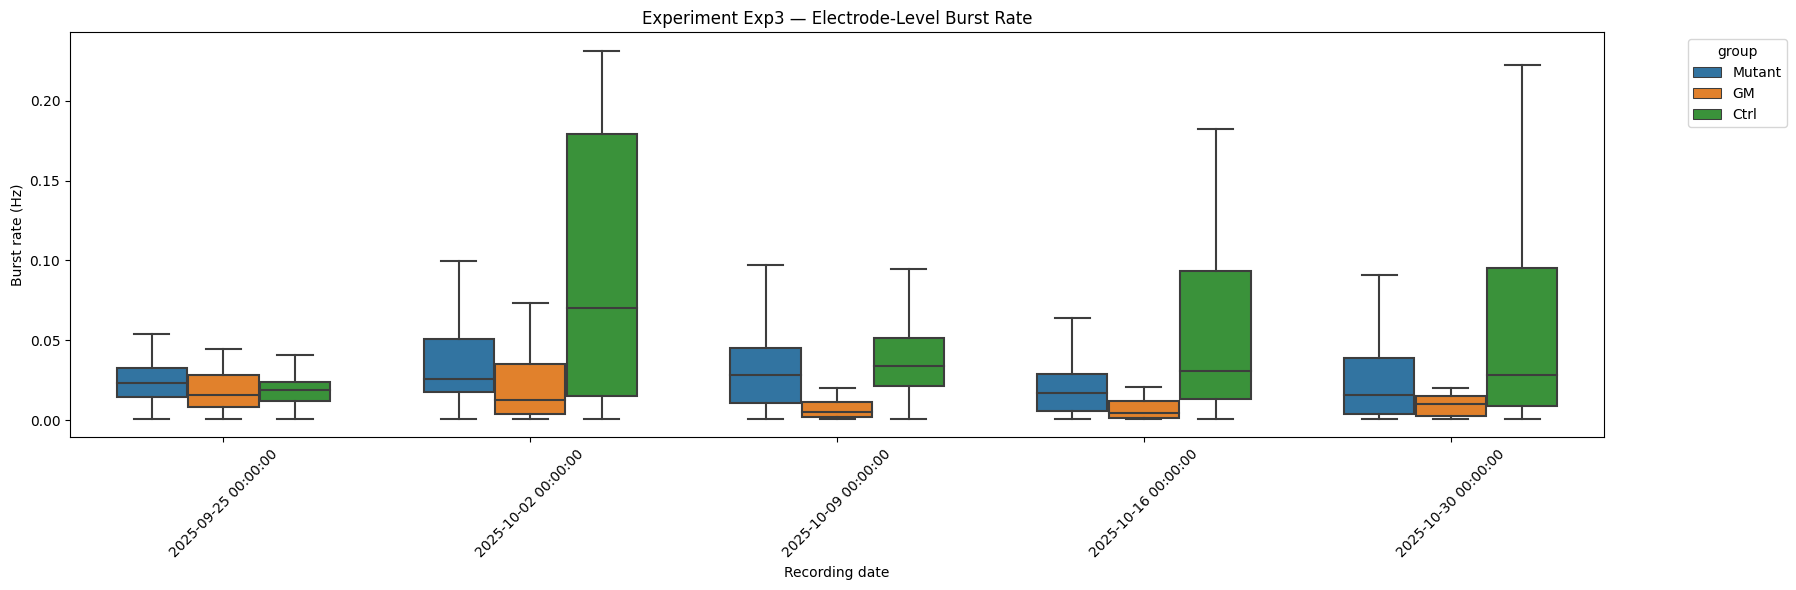

 → Plotting network (groups)

=== Plotting Experiment Exp3 ===


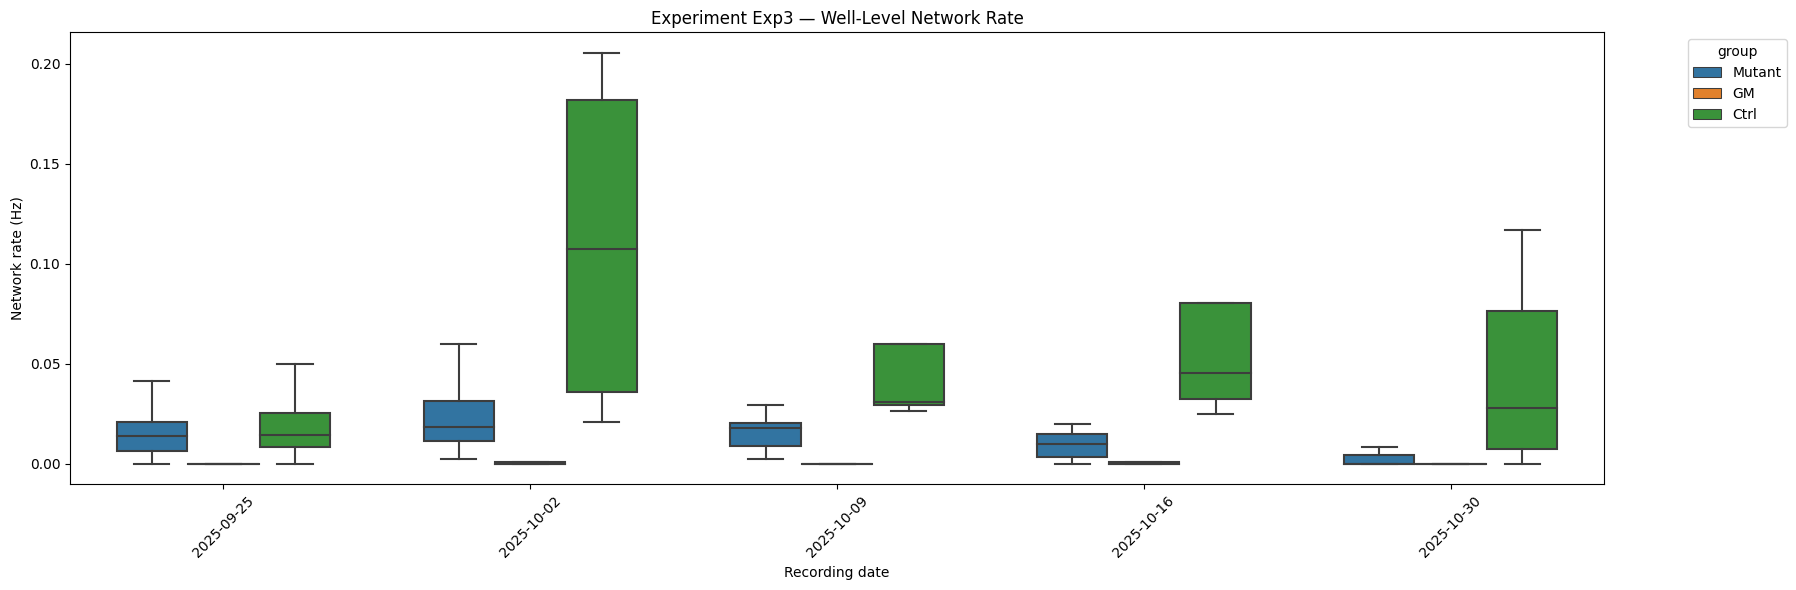

 → Plotting synchrony (groups)

=== Plotting Experiment Exp3 ===


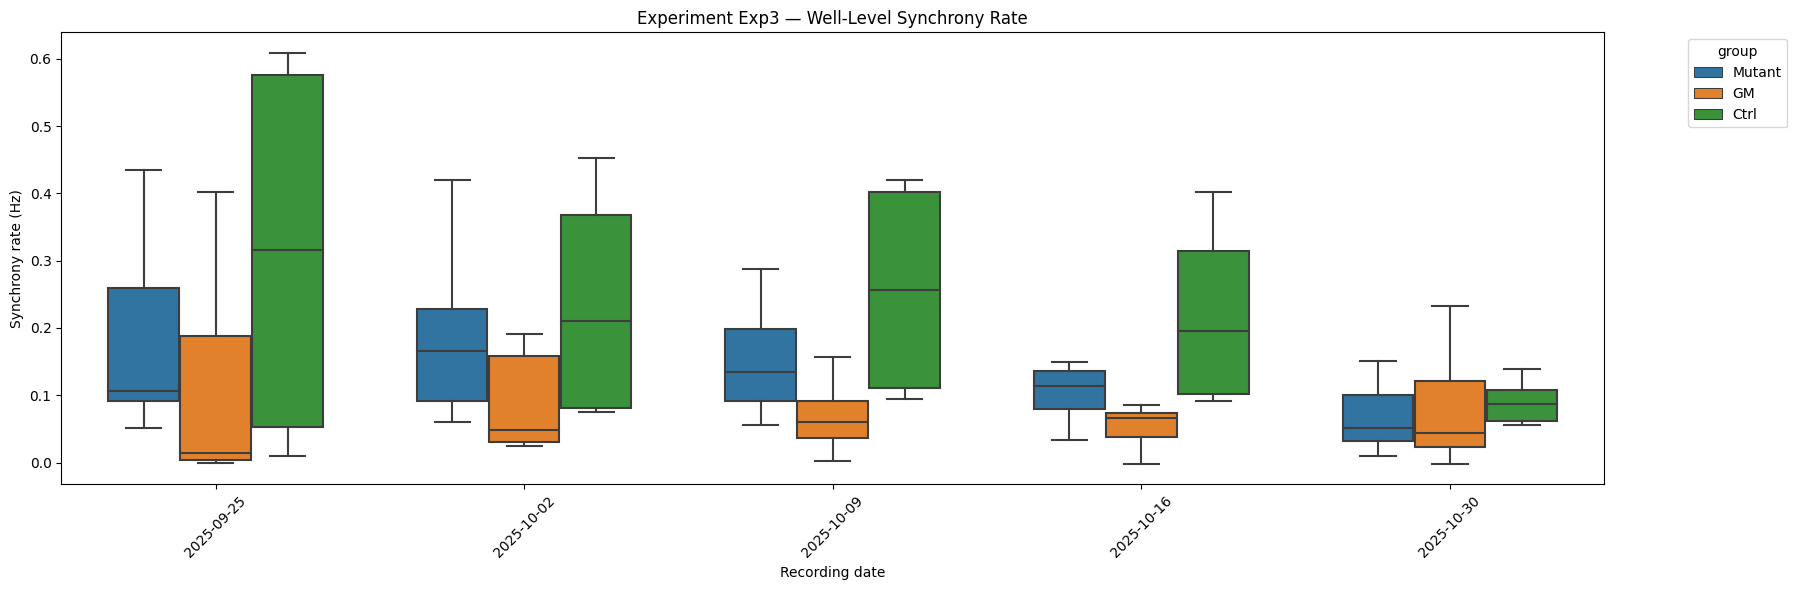


### RUNNING STATISTICS — CELL LINES ###

===== CELL LINE STATS: FIRING =====

  WELL-LEVEL POST-HOC t-tests:
  group1 group2     mean1     mean2  difference         t         p_raw  \
0     C3    C30  0.386751  0.827228   -0.440477 -3.073306  4.490210e-03   
1     C3    C71  0.386751  0.424817   -0.038066 -0.457116  6.490824e-01   
2     C3     GM  0.386751  0.057527    0.329224  6.228323  2.519833e-07   
3    C30    C71  0.827228  0.424817    0.402411  2.701770  1.067308e-02   
4    C30     GM  0.827228  0.057527    0.769701  5.730063  7.315058e-06   
5    C71     GM  0.424817  0.057527    0.367290  5.514198  2.763954e-06   

      p_fmt    p_bonf p_bonf_fmt  
0  0.004490  0.026941   0.026941  
1  0.649082  1.000000   1.000000  
2  0.000000  0.000002   0.000002  
3  0.010673  0.064038   0.064038  
4  0.000007  0.000044   0.000044  
5  0.000003  0.000017   0.000017  

===== CELL LINE STATS: BURST =====

  WELL-LEVEL POST-HOC t-tests:
  group1 group2     mean1     mean2  difference    

In [33]:
results_exp1 = run_full_mea_analysis(
    big_df,
    experiment='Exp3',
    assign_groups=True,
    use_group_for_plate_map=True,
    double_label=True
)


#### REMOVE SAME LINES AS RNAseq

In [17]:
big_df

,well,firing_rate_stats_hz,burst_rate_stats_hz,network_event_rate_hz,synchrony_index,electrodes,firing_rate_vector_hz,burst_rate_vector_hz,recording_date,recording_date_str,plate_name,cell_line,organoid_age_days,spike_list_path,experiment
0,A1,"[4.017828444082542, 5.087837151042226]","[0.1869410723704701, 0.15790478861256138]",0.071252,0.099785,"[A1_11, A1_12, A1_13, A1_14, A1_15, A1_16, A1_...","[1.7476564118841798, 0.05145987169760892, nan,...","[0.022431226124598757, 0.0006597419448411399, ...",2025-04-14,04.14.2025,MAOA2,C3,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
1,A2,"[1.4391208230357608, 1.6648439676442284]","[0.09436092897565711, 0.09586305971365496]",0.124031,0.022132,"[A2_11, A2_12, A2_13, A2_14, A2_15, A2_16, A2_...","[3.015680429868851, 0.0006597419448411399, 0.0...","[0.19066542205908946, nan, nan, nan, 0.0032987...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
2,A3,"[0.4052027312243695, 0.5762036681376207]","[0.018160265113258748, 0.024168885783248578]",0.003299,0.000282,"[A3_11, A3_12, A3_13, A3_14, A3_15, A3_16, A3_...","[nan, 0.0006597419448411399, 0.000659741944841...","[nan, nan, nan, nan, 0.00791690333809368, nan,...",2025-04-14,04.14.2025,MAOA2,GM,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
3,B1,"[2.0029325617413787, 2.347922067937726]","[0.1179549150855449, 0.11597167105563749]",0.032327,0.007995,"[B1_11, B1_12, B1_13, B1_14, B1_15, B1_16, B1_...","[2.4403854539673766, 0.0006597419448411399, 3....","[0.07653006560157223, nan, 0.16889393787933182...",2025-04-14,04.14.2025,MAOA2,C71,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
4,B2,"[1.821286102520696, 3.2362072623431377]","[0.1274676415928486, 0.11408226907420285]",0.148442,0.013659,"[B2_11, B2_12, B2_13, B2_14, B2_15, B2_16, B2_...","[0.0013194838896822799, 3.5289596629552578, 0....","[nan, 0.20188103512138883, nan, nan, 0.0936833...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1047,A4,"[0.004241748910561047, 0.009775569618114778]","[nan, nan]",0.000000,0.232831,"[A4_11, A4_12, A4_13, A4_14, A4_15, A4_16, A4_...","[0.0008220443625118308, nan, 0.000822044362511...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,GM,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
1048,B1,"[0.26199502345978026, 0.7419211332715153]","[0.02757010323501217, 0.025920461645713547]",0.000000,0.046000,"[B1_11, B1_12, B1_13, B1_14, B1_15, B1_16, B1_...","[nan, 0.0008220443625118308, 0.002466133087535...","[nan, nan, nan, nan, 0.01808497597526028, nan,...",2025-10-30,10.30.2025,MAOA76,C3,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
1049,B2,"[0.4753718139533415, 1.490921272006652]","[0.03565617422395066, 0.04528512776359013]",0.000000,0.037999,"[B2_11, B2_12, B2_13, B2_14, B2_15, B2_16, B2_...","[0.024661330875354926, 0.17920567102757912, 0....","[nan, 0.007398399262606477, 0.0024661330875354...",2025-10-30,10.30.2025,MAOA76,C71,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
1050,B4,"[0.010609510053668317, 0.045617147944364]","[0.01808497597526028, 0.0]",0.000000,-0.001633,"[B4_11, B4_12, B4_13, B4_14, B4_15, B4_16, B4_...","[0.004932266175070985, 0.0008220443625118308, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,GM,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3


In [18]:
#old 
"""
REMOVALS = {
    "MAOA72": {"C12", "C30", "C54"},
    "MAOA76": {"C12", "C90"},
    "MAOA77": {"C71", "C90"},
}
"""

'\nREMOVALS = {\n    "MAOA72": {"C12", "C30", "C54"},\n    "MAOA76": {"C12", "C90"},\n    "MAOA77": {"C71", "C90"},\n}\n'

In [19]:
REMOVALS = {
    "MAOA72": { "C30"}
}

In [39]:
df_clean = remove_clones_by_plate(big_df, REMOVALS)

Removed 12 rows based on plate-specific clone removal.


In [40]:
"""
results_exp1_rem = run_full_mea_analysis(
    df_clean,
    experiment="Exp1",
    assign_groups=True,
    use_group_for_plate_map=True,
    double_label=True
)
"""

'\nresults_exp1_rem = run_full_mea_analysis(\n    df_clean,\n    experiment="Exp1",\n    assign_groups=True,\n    use_group_for_plate_map=True,\n    double_label=True\n)\n'

In [41]:
"""results_exp2_rem = run_full_mea_analysis(
    df_clean,
    experiment="Exp2",
    assign_groups=True,
    use_group_for_plate_map=True,
    double_label=True
)
"""

'results_exp2_rem = run_full_mea_analysis(\n    df_clean,\n    experiment="Exp2",\n    assign_groups=True,\n    use_group_for_plate_map=True,\n    double_label=True\n)\n'

In [42]:
"""results_exp3_rem = run_full_mea_analysis(
    df_clean,
    experiment="Exp3",
    assign_groups=True,
    use_group_for_plate_map=True,
    double_label=True
)
"""

'results_exp3_rem = run_full_mea_analysis(\n    df_clean,\n    experiment="Exp3",\n    assign_groups=True,\n    use_group_for_plate_map=True,\n    double_label=True\n)\n'